In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Library berhasil dipanggil!")
print("Persiapan analisis dataset sensor dimulai.")


Library berhasil dipanggil!
Persiapan analisis dataset sensor dimulai.


In [15]:

import pandas as pd
import numpy as np

# Lokasi dataset
file_path = "../dataset/DATA SENSOR.csv"

# Membaca dataset
df = pd.read_csv(file_path)

print("Dataset berhasil dibaca!")
print("Jumlah data:", len(df))



Dataset berhasil dibaca!
Jumlah data: 38531


In [16]:

df.head()


,id_monitoring_udara,suhu,kelembaban,pm10,pm25,barometer,tvoc,waktu_tercatat
0,164460,29.39,46,8.0,3.0,701.29,740.63,2026-01-19 11:40:18
1,164461,29.29,46,5.0,2.0,701.27,740.63,2026-01-19 11:41:22
2,164462,29.39,45,1.0,0.0,701.26,740.63,2026-01-19 11:42:27
3,164463,29.39,45,4.0,1.0,701.26,740.63,2026-01-19 11:43:31
4,164464,29.29,44,0.0,0.0,701.27,740.63,2026-01-19 11:44:36


In [17]:

print("Ukuran dataset:", df.shape)

print("\nNama kolom:")
print(df.columns.tolist())

print("\nInformasi dataset:")
df.info()


Ukuran dataset: (38531, 8)

Nama kolom:
['id_monitoring_udara', 'suhu', 'kelembaban', 'pm10', 'pm25', 'barometer', 'tvoc', 'waktu_tercatat']

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 38531 entries, 0 to 38530
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id_monitoring_udara  38531 non-null  int64  
 1   suhu                 38531 non-null  float64
 2   kelembaban           38531 non-null  int64  
 3   pm10                 38531 non-null  float64
 4   pm25                 38531 non-null  float64
 5   barometer            38531 non-null  float64
 6   tvoc                 38531 non-null  float64
 7   waktu_tercatat       38531 non-null  str    
dtypes: float64(5), int64(2), str(1)
memory usage: 2.4 MB


In [18]:

df.describe()


,id_monitoring_udara,suhu,kelembaban,pm10,pm25,barometer,tvoc
count,38531.000000,38531.000000,38531.000000,38531.000000,38531.000000,38531.000000,38531.000000
mean,183725.000000,27.293052,57.957748,33.058265,15.831850,705.860030,687.483534
std,11123.085948,4.962796,12.579237,15.974734,7.411342,19.702163,230.909944
min,164460.000000,13.800000,21.000000,0.000000,0.000000,650.430000,83.450000
25%,174092.500000,23.930000,49.000000,20.000000,11.000000,700.090000,713.870000
50%,183725.000000,26.220000,61.000000,32.000000,16.000000,702.020000,731.700000
75%,193357.500000,30.090000,68.000000,44.000000,21.000000,703.710000,749.560000
max,202990.000000,44.780000,79.000000,489.000000,221.000000,758.110000,1366.630000


In [19]:

print("Jumlah data kosong setiap kolom:")
print(df.isnull().sum())


Jumlah data kosong setiap kolom:
id_monitoring_udara    0
suhu                   0
kelembaban             0
pm10                   0
pm25                   0
barometer              0
tvoc                   0
waktu_tercatat         0
dtype: int64


In [20]:

print("Jumlah baris duplikat:", df.duplicated().sum())


Jumlah baris duplikat: 0


In [21]:

# Memeriksa tipe data setiap kolom
print(df.dtypes)

# Memeriksa contoh waktu pencatatan
print(df["waktu_tercatat"].head(10))


id_monitoring_udara      int64
suhu                   float64
kelembaban               int64
pm10                   float64
pm25                   float64
barometer              float64
tvoc                   float64
waktu_tercatat             str
dtype: object
0    2026-01-19 11:40:18
1    2026-01-19 11:41:22
2    2026-01-19 11:42:27
3    2026-01-19 11:43:31
4    2026-01-19 11:44:36
5    2026-01-19 11:45:41
6    2026-01-19 11:46:45
7    2026-01-19 11:47:51
8    2026-01-19 11:48:58
9    2026-01-19 11:50:02
Name: waktu_tercatat, dtype: str


In [22]:
# Mengubah kolom waktu menjadi format datetime
df["waktu_tercatat"] = pd.to_datetime(df["waktu_tercatat"])

# Memastikan perubahan berhasil
print("Tipe data waktu:", df["waktu_tercatat"].dtype)

# Menampilkan 10 data pertama
display(df[["waktu_tercatat"]].head(10))

Tipe data waktu: datetime64[us]


,waktu_tercatat
0,2026-01-19 11:40:18
1,2026-01-19 11:41:22
2,2026-01-19 11:42:27
3,2026-01-19 11:43:31
4,2026-01-19 11:44:36
5,2026-01-19 11:45:41
6,2026-01-19 11:46:45
7,2026-01-19 11:47:51
8,2026-01-19 11:48:58
9,2026-01-19 11:50:02


In [23]:
# Menghitung selisih waktu antar pembacaan sensor
df["selisih_waktu"] = df["waktu_tercatat"].diff().dt.total_seconds()

print("Rata-rata interval pembacaan (detik):")
print(df["selisih_waktu"].mean())

print("\nSelisih waktu terbesar:")
print(df["selisih_waktu"].max())

print("\nSelisih waktu terkecil:")
print(df["selisih_waktu"].min())

display(df[["waktu_tercatat", "selisih_waktu"]].head(15))

Rata-rata interval pembacaan (detik):
675.0698416818063

Selisih waktu terbesar:
3716448.0

Selisih waktu terkecil:
13.0


,waktu_tercatat,selisih_waktu
0,2026-01-19 11:40:18,NaN
1,2026-01-19 11:41:22,64.0
2,2026-01-19 11:42:27,65.0
3,2026-01-19 11:43:31,64.0
4,2026-01-19 11:44:36,65.0
5,2026-01-19 11:45:41,65.0
6,2026-01-19 11:46:45,64.0
7,2026-01-19 11:47:51,66.0
8,2026-01-19 11:48:58,67.0
9,2026-01-19 11:50:02,64.0


In [24]:
df["waktu_tercatat"] = pd.to_datetime(df["waktu_tercatat"])

print("Tipe data waktu:", df["waktu_tercatat"].dtype)

display(df[["waktu_tercatat"]].head(10))

Tipe data waktu: datetime64[us]


,waktu_tercatat
0,2026-01-19 11:40:18
1,2026-01-19 11:41:22
2,2026-01-19 11:42:27
3,2026-01-19 11:43:31
4,2026-01-19 11:44:36
5,2026-01-19 11:45:41
6,2026-01-19 11:46:45
7,2026-01-19 11:47:51
8,2026-01-19 11:48:58
9,2026-01-19 11:50:02


In [25]:
# Menghitung selisih waktu antar pembacaan sensor
df["selisih_waktu"] = df["waktu_tercatat"].diff().dt.total_seconds()

# Menampilkan hasil pemeriksaan
print("Rata-rata interval (detik):")
print(df["selisih_waktu"].mean())

print("\nInterval terkecil (detik):")
print(df["selisih_waktu"].min())

print("\nInterval terbesar (detik):")
print(df["selisih_waktu"].max())

print("\n15 data pertama:")
display(df[["waktu_tercatat", "selisih_waktu"]].head(15))

Rata-rata interval (detik):
675.0698416818063

Interval terkecil (detik):
13.0

Interval terbesar (detik):
3716448.0

15 data pertama:


,waktu_tercatat,selisih_waktu
0,2026-01-19 11:40:18,NaN
1,2026-01-19 11:41:22,64.0
2,2026-01-19 11:42:27,65.0
3,2026-01-19 11:43:31,64.0
4,2026-01-19 11:44:36,65.0
5,2026-01-19 11:45:41,65.0
6,2026-01-19 11:46:45,64.0
7,2026-01-19 11:47:51,66.0
8,2026-01-19 11:48:58,67.0
9,2026-01-19 11:50:02,64.0


In [26]:
# Menghitung data kosong
print("Jumlah data kosong:")
print(df.isnull().sum())

# Menghitung baris duplikat
print("\nJumlah baris duplikat:")
print(df.duplicated().sum())

# Memeriksa ID yang duplikat
print("\nJumlah ID duplikat:")
print(df["id_monitoring_udara"].duplicated().sum())

Jumlah data kosong:
id_monitoring_udara    0
suhu                   0
kelembaban             0
pm10                   0
pm25                   0
barometer              0
tvoc                   0
waktu_tercatat         0
selisih_waktu          1
dtype: int64

Jumlah baris duplikat:
0

Jumlah ID duplikat:
0


In [27]:
# Memilih kolom sensor
kolom_sensor = [
    "suhu",
    "kelembaban",
    "pm10",
    "pm25",
    "barometer",
    "tvoc"
]

# Statistik deskriptif
statistik = df[kolom_sensor].describe().T

display(statistik)

,count,mean,std,min,25%,50%,75%,max
suhu,38531.0,27.293052,4.962796,13.80,23.93,26.22,30.09,44.78
kelembaban,38531.0,57.957748,12.579237,21.00,49.00,61.00,68.00,79.00
pm10,38531.0,33.058265,15.974734,0.00,20.00,32.00,44.00,489.00
pm25,38531.0,15.831850,7.411342,0.00,11.00,16.00,21.00,221.00
barometer,38531.0,705.860030,19.702163,650.43,700.09,702.02,703.71,758.11
tvoc,38531.0,687.483534,230.909944,83.45,713.87,731.70,749.56,1366.63


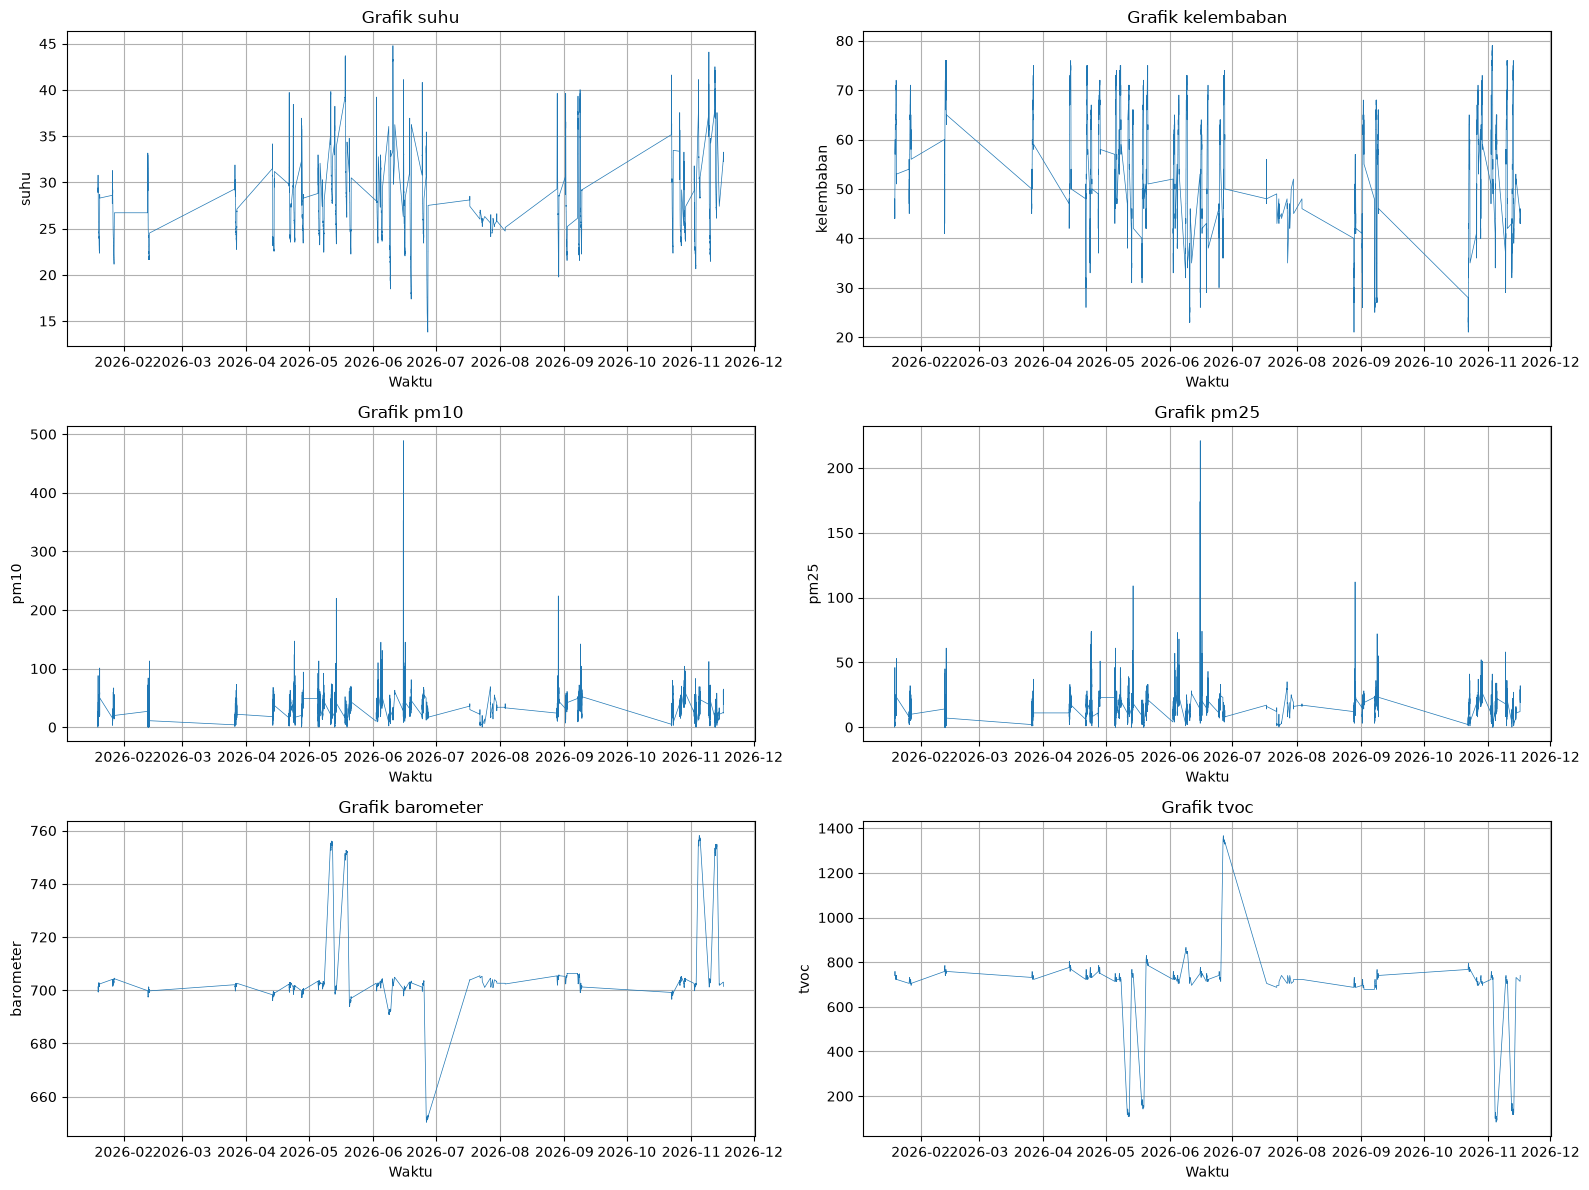

In [28]:
import matplotlib.pyplot as plt

# Mengurutkan data berdasarkan waktu
df = df.sort_values("waktu_tercatat")

kolom_sensor = [
    "suhu",
    "kelembaban",
    "pm10",
    "pm25",
    "barometer",
    "tvoc"
]

# Membuat grafik seluruh sensor
fig, axes = plt.subplots(3, 2, figsize=(16, 12))

for kolom, ax in zip(kolom_sensor, axes.flatten()):
    ax.plot(df["waktu_tercatat"], df[kolom], linewidth=0.5)
    ax.set_title("Grafik " + kolom)
    ax.set_xlabel("Waktu")
    ax.set_ylabel(kolom)
    ax.grid(True)

plt.tight_layout()
plt.show()

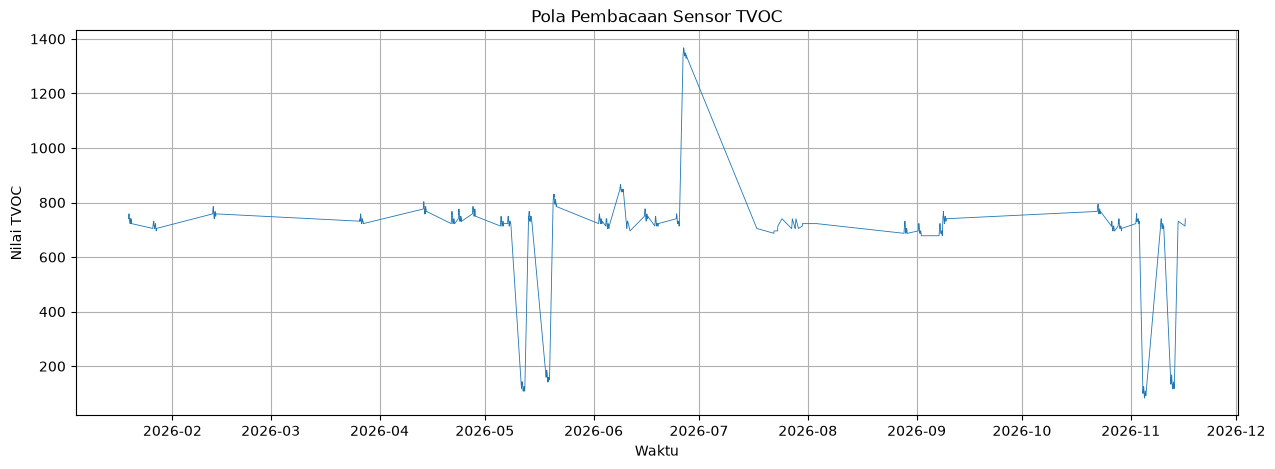

In [29]:
plt.figure(figsize=(15, 5))

plt.plot(
    df["waktu_tercatat"],
    df["tvoc"],
    linewidth=0.6
)

plt.title("Pola Pembacaan Sensor TVOC")
plt.xlabel("Waktu")
plt.ylabel("Nilai TVOC")
plt.grid(True)

plt.show()

In [30]:
# Menghitung kuartil TVOC
Q1 = df["tvoc"].quantile(0.25)
Q3 = df["tvoc"].quantile(0.75)

# Menghitung IQR
IQR = Q3 - Q1

# Menentukan batas bawah dan atas
batas_bawah = Q1 - (1.5 * IQR)
batas_atas = Q3 + (1.5 * IQR)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("\nBatas bawah:", batas_bawah)
print("Batas atas:", batas_atas)

# Mengidentifikasi kandidat anomali
anomali_tvoc = df[
    (df["tvoc"] < batas_bawah) |
    (df["tvoc"] > batas_atas)
]

print("\nJumlah kandidat anomali TVOC:", len(anomali_tvoc))

# Menampilkan 20 kandidat anomali
display(
    anomali_tvoc[
        ["waktu_tercatat", "tvoc"]
    ].head(20)
)

Q1: 713.87
Q3: 749.56
IQR: 35.68999999999994

Batas bawah: 660.335
Batas atas: 803.0949999999998

Jumlah kandidat anomali TVOC: 7599


,waktu_tercatat,tvoc
4857,2026-04-13 14:32:52,803.32
4858,2026-04-13 14:33:55,803.32
4859,2026-04-13 14:34:58,803.32
4860,2026-04-13 14:37:18,803.32
4861,2026-04-13 14:38:21,803.32
4862,2026-04-13 14:39:25,803.32
4863,2026-04-13 14:40:28,803.32
4864,2026-04-13 14:41:31,803.32
4865,2026-04-13 14:42:34,803.32
4866,2026-04-13 14:43:37,803.32


In [31]:
# Menghitung kuartil TVOC
Q1 = df["tvoc"].quantile(0.25)
Q3 = df["tvoc"].quantile(0.75)

# Menghitung IQR
IQR = Q3 - Q1

# Menentukan batas anomali
batas_bawah = Q1 - (1.5 * IQR)
batas_atas = Q3 + (1.5 * IQR)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("\nBatas bawah:", batas_bawah)
print("Batas atas:", batas_atas)

# Mengidentifikasi kandidat anomali
anomali_tvoc = df[
    (df["tvoc"] < batas_bawah) |
    (df["tvoc"] > batas_atas)
]

print("\nJumlah kandidat anomali TVOC:", len(anomali_tvoc))

# Menampilkan 20 data kandidat anomali
display(
    anomali_tvoc[
        ["waktu_tercatat", "tvoc"]
    ].head(20)
)

Q1: 713.87
Q3: 749.56
IQR: 35.68999999999994

Batas bawah: 660.335
Batas atas: 803.0949999999998

Jumlah kandidat anomali TVOC: 7599


,waktu_tercatat,tvoc
4857,2026-04-13 14:32:52,803.32
4858,2026-04-13 14:33:55,803.32
4859,2026-04-13 14:34:58,803.32
4860,2026-04-13 14:37:18,803.32
4861,2026-04-13 14:38:21,803.32
4862,2026-04-13 14:39:25,803.32
4863,2026-04-13 14:40:28,803.32
4864,2026-04-13 14:41:31,803.32
4865,2026-04-13 14:42:34,803.32
4866,2026-04-13 14:43:37,803.32


In [32]:
# Memisahkan kandidat anomali bawah dan atas
anomali_bawah = df[df["tvoc"] < batas_bawah]
anomali_atas = df[df["tvoc"] > batas_atas]

print("Jumlah anomali bawah:", len(anomali_bawah))
print("Jumlah anomali atas:", len(anomali_atas))

print("\nStatistik anomali bawah:")
display(anomali_bawah["tvoc"].describe())

print("\nStatistik anomali atas:")
display(anomali_atas["tvoc"].describe())

print("\nContoh anomali bawah:")
display(
    anomali_bawah[["waktu_tercatat", "tvoc"]].head(10)
)

print("\nContoh anomali atas:")
display(
    anomali_atas[["waktu_tercatat", "tvoc"]].head(10)
)

Jumlah anomali bawah: 4526
Jumlah anomali atas: 3073

Statistik anomali bawah:


count    4526.000000
mean      132.243774
std        24.616740
min        83.450000
25%       117.010000
50%       125.420000
75%       150.690000
max       184.480000
Name: tvoc, dtype: float64


Statistik anomali atas:


count    3073.000000
mean     1037.596118
std       251.395049
min       803.320000
25%       830.310000
50%       857.370000
75%      1347.660000
max      1366.630000
Name: tvoc, dtype: float64


Contoh anomali bawah:


,waktu_tercatat,tvoc
11384,2026-05-11 10:33:22,117.01
11385,2026-05-11 10:34:25,117.01
11386,2026-05-11 10:35:28,117.01
11387,2026-05-11 10:36:31,117.01
11388,2026-05-11 10:37:34,117.01
11389,2026-05-11 10:38:37,117.01
11390,2026-05-11 10:39:40,117.01
11391,2026-05-11 11:40:35,125.42
11392,2026-05-11 11:41:38,125.42
11393,2026-05-11 11:42:42,125.42



Contoh anomali atas:


,waktu_tercatat,tvoc
4857,2026-04-13 14:32:52,803.32
4858,2026-04-13 14:33:55,803.32
4859,2026-04-13 14:34:58,803.32
4860,2026-04-13 14:37:18,803.32
4861,2026-04-13 14:38:21,803.32
4862,2026-04-13 14:39:25,803.32
4863,2026-04-13 14:40:28,803.32
4864,2026-04-13 14:41:31,803.32
4865,2026-04-13 14:42:34,803.32
4866,2026-04-13 14:43:37,803.32


In [33]:
# Mengurutkan data berdasarkan waktu
df = df.sort_values("waktu_tercatat").copy()

# Memberikan nomor kelompok setiap kali nilai TVOC berubah
df["kelompok_tvoc"] = (
    df["tvoc"] != df["tvoc"].shift()
).cumsum()

# Menghitung durasi pengulangan nilai TVOC
pola_tvoc = df.groupby("kelompok_tvoc").agg(
    nilai_tvoc=("tvoc", "first"),
    waktu_mulai=("waktu_tercatat", "first"),
    waktu_akhir=("waktu_tercatat", "last"),
    jumlah_pengulangan=("tvoc", "size")
).reset_index(drop=True)

# Mengurutkan berdasarkan jumlah pengulangan
pola_tvoc = pola_tvoc.sort_values(
    "jumlah_pengulangan",
    ascending=False
)

print("20 kelompok TVOC dengan pengulangan terpanjang:")

display(pola_tvoc.head(20))

20 kelompok TVOC dengan pengulangan terpanjang:


,nilai_tvoc,waktu_mulai,waktu_akhir,jumlah_pengulangan
932,731.70,2026-11-02 18:06:52,2026-11-03 01:16:37,399
546,848.34,2026-06-08 23:31:25,2026-06-09 05:42:45,327
682,1347.66,2026-06-27 00:28:21,2026-06-27 06:11:34,310
626,722.78,2026-06-19 00:14:54,2026-06-19 05:57:58,303
901,713.87,2026-10-29 00:37:37,2026-10-29 05:45:51,294
900,704.97,2026-10-28 19:41:26,2026-10-29 00:36:34,280
488,740.63,2026-06-04 12:51:47,2026-06-04 17:40:42,257
283,713.87,2026-05-05 19:45:20,2026-05-06 00:50:57,253
321,731.70,2026-05-08 01:24:58,2026-05-08 06:25:10,247
401,159.13,2026-05-19 01:10:35,2026-05-19 06:04:01,237


In [34]:
# Mengurutkan data berdasarkan waktu
df = df.sort_values("waktu_tercatat").copy()

# Menghitung jumlah perubahan nilai setiap sensor
kolom_sensor = [
    "suhu",
    "kelembaban",
    "pm10",
    "pm25",
    "barometer",
    "tvoc"
]

for kolom in kolom_sensor:
    jumlah_perubahan = (df[kolom] != df[kolom].shift()).sum()

    print(
        f"{kolom}: {jumlah_perubahan:,} perubahan "
        f"dari {len(df):,} data"
    )

suhu: 13,253 perubahan dari 38,531 data
kelembaban: 10,334 perubahan dari 38,531 data
pm10: 32,615 perubahan dari 38,531 data
pm25: 25,306 perubahan dari 38,531 data
barometer: 31,676 perubahan dari 38,531 data
tvoc: 1,097 perubahan dari 38,531 data


In [35]:
# Menghitung jumlah nilai TVOC yang berbeda
jumlah_unik = df["tvoc"].nunique()

print("Jumlah seluruh data:", len(df))
print("Jumlah nilai TVOC unik:", jumlah_unik)

# Menghitung frekuensi setiap nilai TVOC
frekuensi_tvoc = (
    df["tvoc"]
    .value_counts()
    .reset_index()
)

frekuensi_tvoc.columns = [
    "nilai_tvoc",
    "jumlah_kemunculan"
]

# Menampilkan 20 nilai yang paling sering muncul
display(frekuensi_tvoc.head(20))

Jumlah seluruh data: 38531
Jumlah nilai TVOC unik: 40


,nilai_tvoc,jumlah_kemunculan
0,731.70,5131
1,722.78,4510
2,713.87,3573
3,740.63,3531
4,749.56,3034
5,704.97,2361
6,758.50,2104
7,767.45,1787
8,696.08,1385
9,776.40,1162


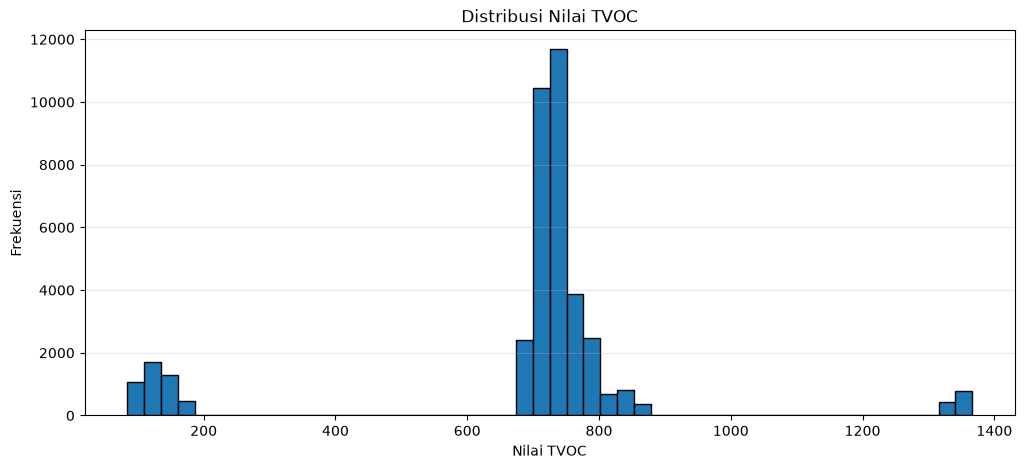

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.hist(
    df["tvoc"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribusi Nilai TVOC")
plt.xlabel("Nilai TVOC")
plt.ylabel("Frekuensi")
plt.grid(axis="y", alpha=0.3)

plt.show()

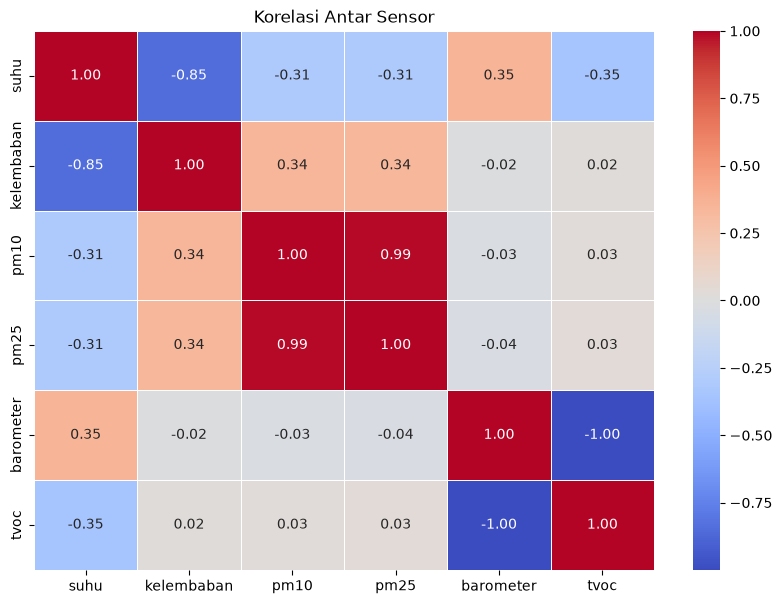

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt

# Memilih kolom sensor
kolom_sensor = [
    "suhu",
    "kelembaban",
    "pm10",
    "pm25",
    "barometer",
    "tvoc"
]

# Menghitung korelasi antar sensor
korelasi = df[kolom_sensor].corr()

# Membuat heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    korelasi,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Korelasi Antar Sensor")
plt.show()

In [38]:
import numpy as np

# Menghitung korelasi dengan presisi lebih tinggi
nilai_korelasi = df["barometer"].corr(df["tvoc"])

print("Korelasi Barometer dan TVOC:", nilai_korelasi)

# Membuat persamaan hubungan linear
x = df["tvoc"]
y = df["barometer"]

slope, intercept = np.polyfit(x, y, 1)

# Menghitung nilai prediksi
y_prediksi = slope * x + intercept

# Menghitung selisih nilai aktual dan prediksi
selisih = np.abs(y - y_prediksi)

print("\nPersamaan hubungan:")
print(f"Barometer = {slope:.6f} * TVOC + {intercept:.6f}")

print("\nPemeriksaan selisih:")
print("Rata-rata selisih:", selisih.mean())
print("Selisih maksimum:", selisih.max())

Korelasi Barometer dan TVOC: -0.9996781714568774

Persamaan hubungan:
Barometer = -0.085297 * TVOC + 764.500004

Pemeriksaan selisih:
Rata-rata selisih: 0.32644405604492116
Selisih maksimum: 2.598821395164123


In [39]:
# Memeriksa hubungan nilai TVOC dengan Barometer
pola_barometer = (
    df.groupby("tvoc")["barometer"]
    .agg([
        "count",
        "nunique",
        "min",
        "max",
        "std"
    ])
    .sort_values("count", ascending=False)
)

print("15 kelompok TVOC dengan frekuensi tertinggi:")
display(pola_barometer.head(15))

# Menghitung jumlah pasangan nilai TVOC-Barometer yang unik
jumlah_pasangan = df[["tvoc", "barometer"]].drop_duplicates().shape[0]

print("Jumlah pasangan TVOC-Barometer unik:", jumlah_pasangan)

15 kelompok TVOC dengan frekuensi tertinggi:


,count,nunique,min,max,std
tvoc,,,,,
731.70,5131,75,701.54,702.28,0.218184
722.78,4510,77,702.28,703.04,0.214978
713.87,3573,76,703.03,703.78,0.209357
740.63,3531,75,700.79,701.53,0.218422
749.56,3034,75,700.04,700.78,0.216699
704.97,2361,76,703.78,704.53,0.215338
758.50,2104,75,699.29,700.03,0.220029
767.45,1787,76,698.54,699.31,0.219199
696.08,1385,75,704.54,705.28,0.197525


Jumlah pasangan TVOC-Barometer unik: 2489


In [40]:
# Membuat prediksi Barometer berdasarkan TVOC
df["barometer_prediksi"] = (
    -0.085297 * df["tvoc"] + 764.500004
)

# Menghitung selisih nilai aktual dan prediksi
df["selisih_barometer"] = abs(
    df["barometer"] - df["barometer_prediksi"]
)

# Menampilkan statistik selisih
print("Statistik selisih Barometer:")
display(df["selisih_barometer"].describe())

# Menampilkan 10 data dengan selisih terbesar
data_menyimpang = df.sort_values(
    "selisih_barometer",
    ascending=False
)

display(
    data_menyimpang[
        [
            "waktu_tercatat",
            "tvoc",
            "barometer",
            "barometer_prediksi",
            "selisih_barometer"
        ]
    ].head(10)
)

Statistik selisih Barometer:


count    38531.000000
mean         0.326355
std          0.378551
min          0.000299
25%          0.109035
50%          0.234785
75%          0.423214
max          2.599435
Name: selisih_barometer, dtype: float64

,waktu_tercatat,tvoc,barometer,barometer_prediksi,selisih_barometer
23656,2026-06-26 15:51:31,1366.63,650.53,647.930565,2.599435
23660,2026-06-26 15:57:02,1366.63,650.53,647.930565,2.599435
23659,2026-06-26 15:55:59,1366.63,650.53,647.930565,2.599435
23662,2026-06-26 15:59:09,1366.63,650.53,647.930565,2.599435
23628,2026-06-26 15:16:42,1366.63,650.53,647.930565,2.599435
23575,2026-06-26 14:20:47,1366.63,650.53,647.930565,2.599435
23663,2026-06-26 16:00:12,1366.63,650.53,647.930565,2.599435
23622,2026-06-26 15:10:23,1366.63,650.53,647.930565,2.599435
23581,2026-06-26 14:27:06,1366.63,650.52,647.930565,2.589435
23654,2026-06-26 15:49:24,1366.63,650.52,647.930565,2.589435


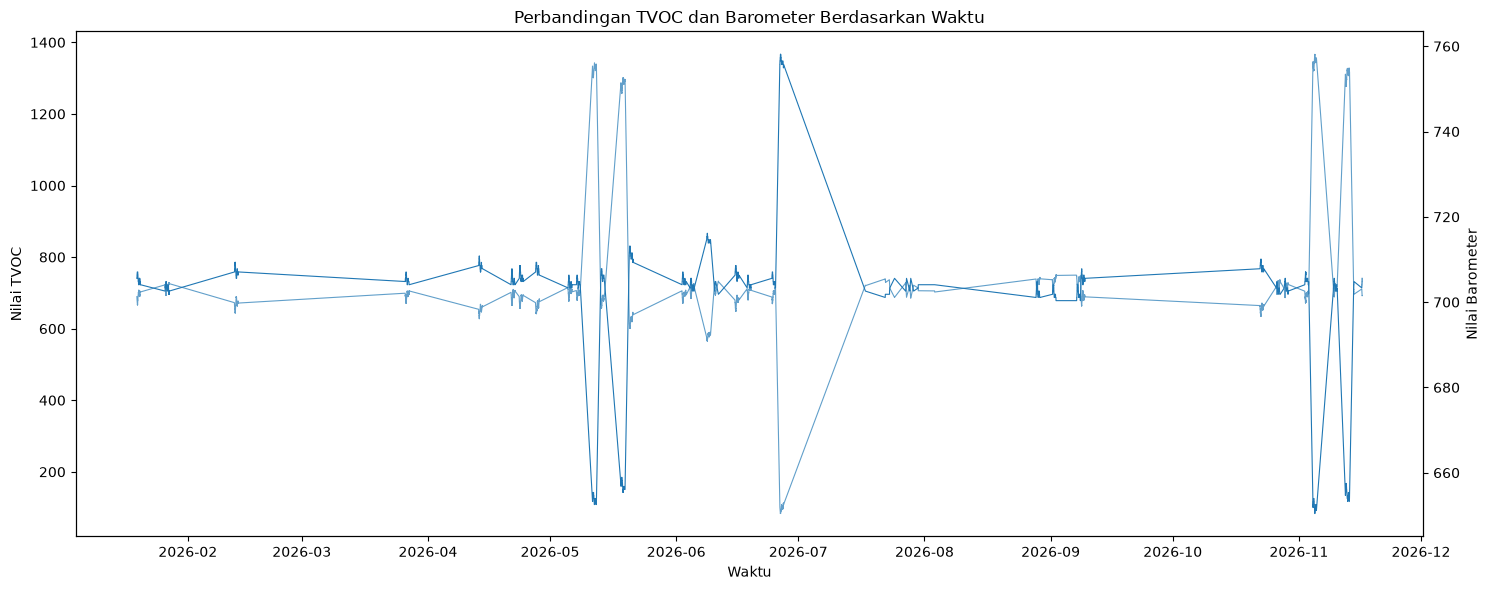

In [41]:
import matplotlib.pyplot as plt

# Mengurutkan data berdasarkan waktu
df_plot = df.sort_values("waktu_tercatat").copy()

fig, ax1 = plt.subplots(figsize=(15, 6))

# Grafik TVOC
ax1.plot(
    df_plot["waktu_tercatat"],
    df_plot["tvoc"],
    label="TVOC",
    linewidth=0.8
)

ax1.set_xlabel("Waktu")
ax1.set_ylabel("Nilai TVOC")
ax1.set_title("Perbandingan TVOC dan Barometer Berdasarkan Waktu")

# Grafik Barometer menggunakan sumbu kedua
ax2 = ax1.twinx()

ax2.plot(
    df_plot["waktu_tercatat"],
    df_plot["barometer"],
    label="Barometer",
    linewidth=0.8,
    alpha=0.7
)

ax2.set_ylabel("Nilai Barometer")

fig.tight_layout()
plt.show()

In [42]:
# Memilih fitur sensor untuk model AI
fitur_sensor = [
    "suhu",
    "kelembaban",
    "pm10",
    "pm25",
    "barometer",
    "tvoc"
]

# Membuat dataset khusus fitur
data_model = df[fitur_sensor].copy()

# Memeriksa dataset fitur
print("Jumlah baris:", data_model.shape[0])
print("Jumlah kolom:", data_model.shape[1])

print("\nPemeriksaan missing value:")
print(data_model.isnull().sum())

print("\nContoh data fitur:")
display(data_model.head())

Jumlah baris: 38531
Jumlah kolom: 6

Pemeriksaan missing value:
suhu          0
kelembaban    0
pm10          0
pm25          0
barometer     0
tvoc          0
dtype: int64

Contoh data fitur:


,suhu,kelembaban,pm10,pm25,barometer,tvoc
0,29.39,46,8.0,3.0,701.29,740.63
1,29.29,46,5.0,2.0,701.27,740.63
2,29.39,45,1.0,0.0,701.26,740.63
3,29.39,45,4.0,1.0,701.26,740.63
4,29.29,44,0.0,0.0,701.27,740.63


In [43]:
# Menentukan batas pembagian data
batas = int(len(data_model) * 0.8)

# Membagi data berdasarkan urutan
X_train = data_model.iloc[:batas].copy()
X_test = data_model.iloc[batas:].copy()

# Menampilkan hasil pembagian
print("Jumlah seluruh data:", len(data_model))
print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

print("\nPersentase pembagian:")
print(f"Training: {len(X_train) / len(data_model) * 100:.2f}%")
print(f"Testing: {len(X_test) / len(data_model) * 100:.2f}%")

Jumlah seluruh data: 38531
Jumlah data training: 30824
Jumlah data testing: 7707

Persentase pembagian:
Training: 80.00%
Testing: 20.00%


In [44]:
from sklearn.ensemble import IsolationForest

# Membuat model Isolation Forest
model = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42
)

# Melatih model menggunakan data training
model.fit(X_train)

print("Model Isolation Forest berhasil dilatih!")

Model Isolation Forest berhasil dilatih!


In [45]:
# Melakukan prediksi pada data testing
hasil_prediksi = model.predict(X_test)

# Menyimpan hasil prediksi
X_test_hasil = X_test.copy()
X_test_hasil["hasil_prediksi"] = hasil_prediksi

print("Prediksi berhasil dilakukan!")
print("\nContoh hasil prediksi:")
display(X_test_hasil.head(10))

Prediksi berhasil dilakukan!

Contoh hasil prediksi:


,suhu,kelembaban,pm10,pm25,barometer,tvoc,hasil_prediksi
30824,30.88,49,32.0,16.0,703.30,713.87,1
30825,30.68,50,32.0,15.0,703.26,713.87,1
30826,30.68,50,32.0,16.0,703.26,713.87,1
30827,30.58,50,32.0,16.0,703.24,713.87,1
30828,30.49,50,29.0,15.0,703.23,713.87,1
30829,30.49,50,33.0,16.0,703.27,713.87,1
30830,30.39,50,31.0,15.0,703.27,713.87,1
30831,30.39,49,28.0,13.0,703.31,713.87,1
30832,30.29,50,24.0,12.0,703.31,713.87,1
30833,30.29,49,23.0,12.0,703.26,713.87,1


In [46]:
# Menghitung jumlah data normal dan anomali
jumlah_normal = (hasil_prediksi == 1).sum()
jumlah_anomali = (hasil_prediksi == -1).sum()

print("Jumlah data testing:", len(hasil_prediksi))
print("Jumlah data normal:", jumlah_normal)
print("Jumlah data terindikasi anomali:", jumlah_anomali)

print("\nPersentase:")
print(f"Normal: {jumlah_normal / len(hasil_prediksi) * 100:.2f}%")
print(f"Anomali: {jumlah_anomali / len(hasil_prediksi) * 100:.2f}%")

Jumlah data testing: 7707
Jumlah data normal: 4797
Jumlah data terindikasi anomali: 2910

Persentase:
Normal: 62.24%
Anomali: 37.76%


In [47]:
# Memisahkan data normal dan anomali
data_normal = X_test_hasil[
    X_test_hasil["hasil_prediksi"] == 1
]

data_anomali = X_test_hasil[
    X_test_hasil["hasil_prediksi"] == -1
]

# Membandingkan rata-rata setiap sensor
perbandingan = pd.DataFrame({
    "Rata-rata Normal": data_normal[fitur_sensor].mean(),
    "Rata-rata Anomali": data_anomali[fitur_sensor].mean()
})

print("Perbandingan rata-rata data normal dan anomali:")
display(perbandingan.round(2))

Perbandingan rata-rata data normal dan anomali:


,Rata-rata Normal,Rata-rata Anomali
suhu,26.25,31.00
kelembaban,62.26,57.77
pm10,36.16,35.12
pm25,17.15,16.97
barometer,702.84,744.93
tvoc,720.91,235.08


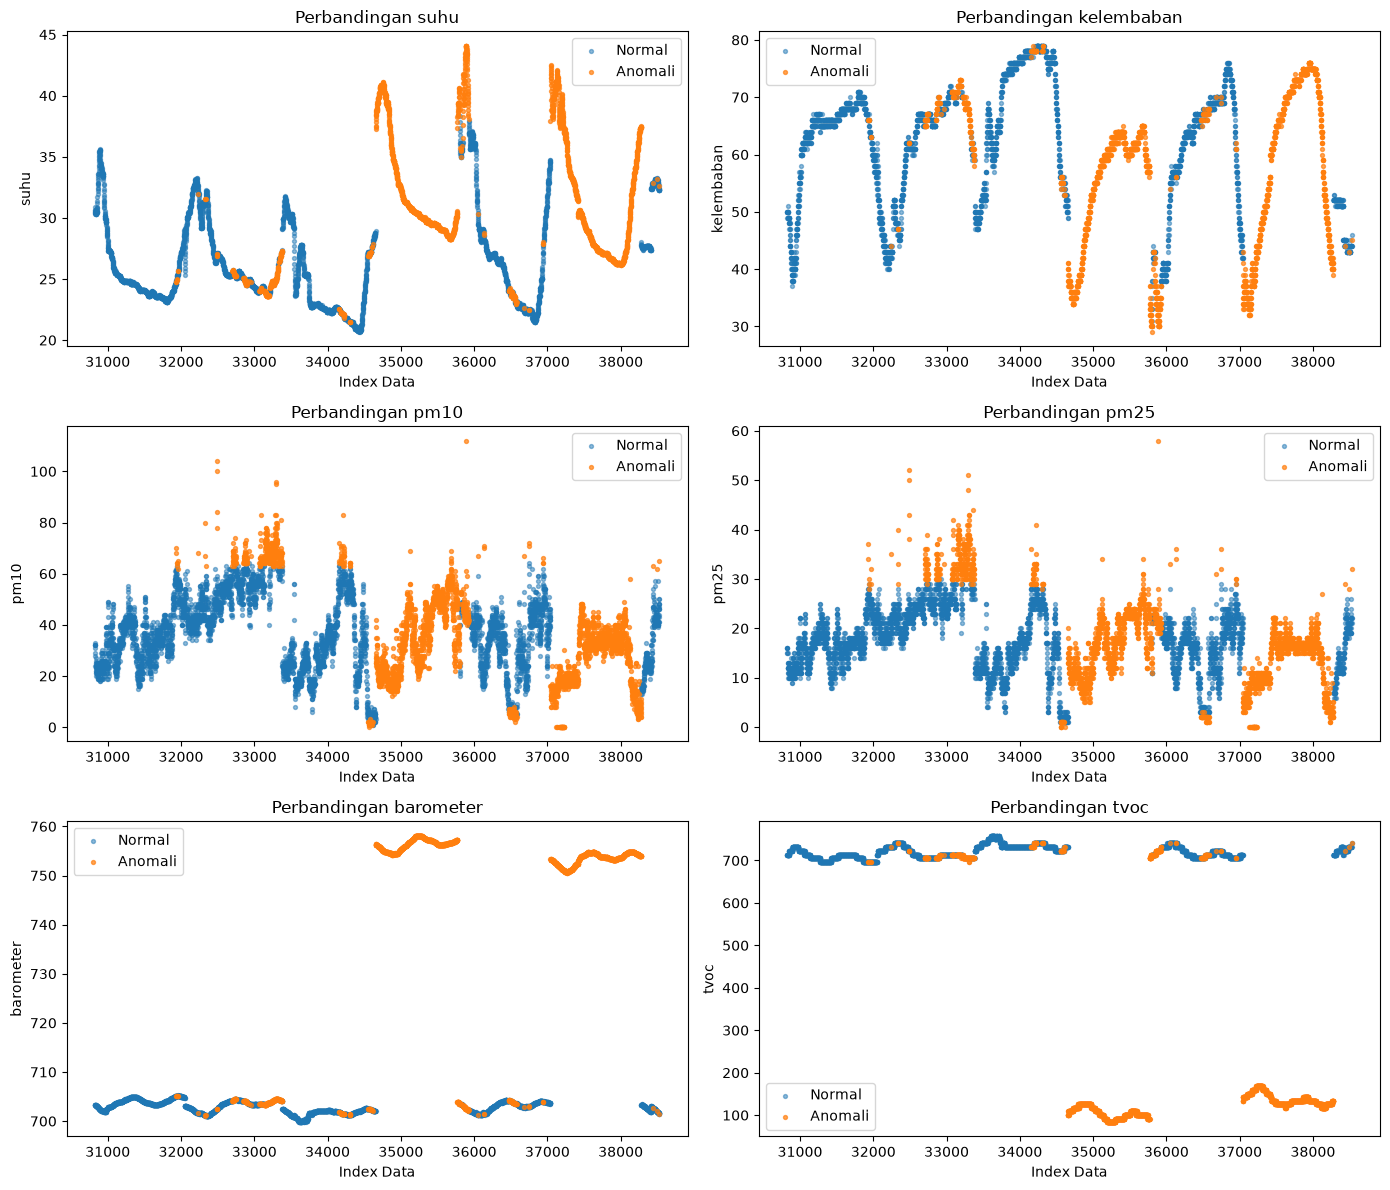

In [48]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for ax, fitur in zip(axes.flatten(), fitur_sensor):

    ax.scatter(
        data_normal.index,
        data_normal[fitur],
        label="Normal",
        s=8,
        alpha=0.5
    )

    ax.scatter(
        data_anomali.index,
        data_anomali[fitur],
        label="Anomali",
        s=8,
        alpha=0.7
    )

    ax.set_title(f"Perbandingan {fitur}")
    ax.set_xlabel("Index Data")
    ax.set_ylabel(fitur)
    ax.legend()

plt.tight_layout()
plt.show()

In [49]:
# Menghitung nilai ekstrem setiap sensor menggunakan IQR

hasil_iqr = []

for fitur in fitur_sensor:
    Q1 = X_test[fitur].quantile(0.25)
    Q3 = X_test[fitur].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    jumlah_ekstrem = (
        (X_test[fitur] < batas_bawah) |
        (X_test[fitur] > batas_atas)
    ).sum()

    hasil_iqr.append({
        "Sensor": fitur,
        "Jumlah Nilai Ekstrem": jumlah_ekstrem,
        "Persentase (%)": round(
            jumlah_ekstrem / len(X_test) * 100, 2
        )
    })

tabel_iqr = pd.DataFrame(hasil_iqr)

display(tabel_iqr)

,Sensor,Jumlah Nilai Ekstrem,Persentase (%)
0,suhu,262,3.40
1,kelembaban,0,0.00
2,pm10,14,0.18
3,pm25,58,0.75
4,barometer,0,0.00
5,tvoc,0,0.00


In [50]:
# Menentukan data ekstrem berdasarkan IQR
mask_iqr = pd.Series(False, index=X_test.index)

for fitur in fitur_sensor:
    Q1 = X_test[fitur].quantile(0.25)
    Q3 = X_test[fitur].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    mask_iqr |= (
        (X_test[fitur] < batas_bawah) |
        (X_test[fitur] > batas_atas)
    )

# Menggabungkan hasil kedua metode
mask_if = X_test_hasil["hasil_prediksi"] == -1

jumlah_keduanya = (mask_iqr & mask_if).sum()
jumlah_iqr_saja = (mask_iqr & ~mask_if).sum()
jumlah_if_saja = (~mask_iqr & mask_if).sum()
jumlah_normal = (~mask_iqr & ~mask_if).sum()

print("Perbandingan IQR dan Isolation Forest")
print("-------------------------------------")
print("Anomali menurut kedua metode:", jumlah_keduanya)
print("Anomali menurut IQR saja:", jumlah_iqr_saja)
print("Anomali menurut Isolation Forest saja:", jumlah_if_saja)
print("Tidak terdeteksi oleh kedua metode:", jumlah_normal)

Perbandingan IQR dan Isolation Forest
-------------------------------------
Anomali menurut kedua metode: 319
Anomali menurut IQR saja: 0
Anomali menurut Isolation Forest saja: 2591
Tidak terdeteksi oleh kedua metode: 4797


In [51]:
# Mengambil data yang hanya terdeteksi Isolation Forest
anomali_if_saja = X_test_hasil[
    (mask_if) & (~mask_iqr)
].copy()

print("Jumlah anomali IF saja:", len(anomali_if_saja))

print("\n10 contoh data:")
display(anomali_if_saja.head(10))

Jumlah anomali IF saja: 2591

10 contoh data:


,suhu,kelembaban,pm10,pm25,barometer,tvoc,hasil_prediksi
31931,24.73,66,70.0,37.0,705.13,696.08,-1
31932,24.73,66,68.0,34.0,705.12,696.08,-1
31939,24.92,66,64.0,28.0,705.12,696.08,-1
31940,24.92,66,64.0,30.0,705.09,696.08,-1
31942,25.02,66,63.0,29.0,705.10,696.08,-1
31963,25.62,63,65.0,32.0,705.19,696.08,-1
31964,25.62,63,62.0,29.0,705.18,696.08,-1
32236,31.97,44,68.0,35.0,701.59,731.70,-1
32333,31.58,47,67.0,33.0,701.17,740.63,-1
32335,31.58,47,63.0,29.0,701.16,740.63,-1


In [52]:
# Menghitung skor anomali data testing
skor_anomali = model.decision_function(X_test)

# Menambahkan skor ke tabel hasil
X_test_hasil["skor_anomali"] = skor_anomali

# Mengurutkan data dari skor paling rendah
data_paling_anomali = X_test_hasil.sort_values(
    by="skor_anomali",
    ascending=True
)

print("10 data dengan skor paling anomali:")
display(data_paling_anomali.head(10))

10 data dengan skor paling anomali:


,suhu,kelembaban,pm10,pm25,barometer,tvoc,hasil_prediksi,skor_anomali
37136,42.00,32,0.0,0.0,752.09,150.69,-1,-0.197078
37138,41.71,33,0.0,0.0,752.11,150.69,-1,-0.196606
37195,39.82,37,0.0,0.0,751.30,159.13,-1,-0.193035
37200,39.52,37,0.0,0.0,751.33,159.13,-1,-0.193035
37199,39.72,37,0.0,0.0,751.31,159.13,-1,-0.193035
37192,39.42,37,0.0,0.0,751.40,159.13,-1,-0.193035
37121,40.51,34,0.0,0.0,752.45,150.69,-1,-0.192377
37197,40.12,38,0.0,0.0,751.31,159.13,-1,-0.191629
37193,39.62,38,0.0,0.0,751.31,159.13,-1,-0.189760
37201,39.42,38,0.0,0.0,751.33,159.13,-1,-0.189760


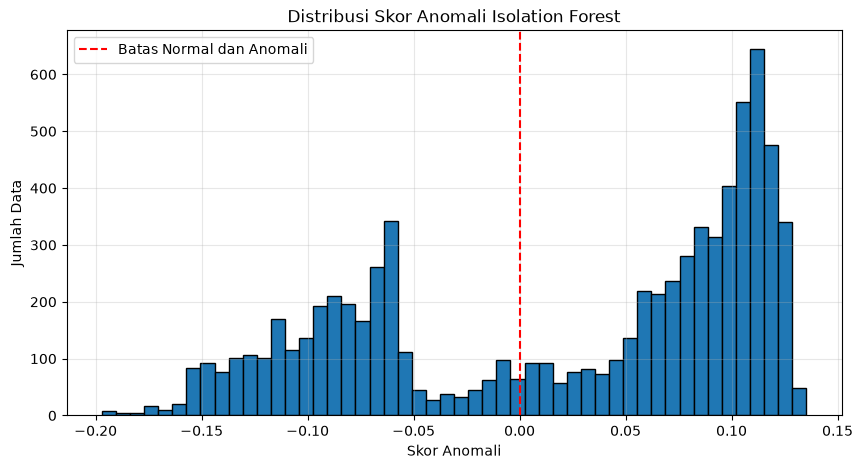

In [53]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    skor_anomali,
    bins=50,
    edgecolor="black"
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="Batas Normal dan Anomali"
)

plt.title("Distribusi Skor Anomali Isolation Forest")
plt.xlabel("Skor Anomali")
plt.ylabel("Jumlah Data")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [54]:
from sklearn.ensemble import IsolationForest

daftar_contamination = [0.05, 0.10, 0.15]

hasil_perbandingan = []

for nilai in daftar_contamination:

    model_uji = IsolationForest(
        n_estimators=100,
        contamination=nilai,
        random_state=42
    )

    model_uji.fit(X_train)

    prediksi = model_uji.predict(X_test)

    jumlah_anomali = (prediksi == -1).sum()
    jumlah_normal = (prediksi == 1).sum()

    hasil_perbandingan.append({
        "Contamination": nilai,
        "Data Normal": jumlah_normal,
        "Data Anomali": jumlah_anomali,
        "Persentase Anomali": round(
            jumlah_anomali / len(X_test) * 100, 2
        )
    })

tabel_perbandingan = pd.DataFrame(hasil_perbandingan)

display(tabel_perbandingan)

,Contamination,Data Normal,Data Anomali,Persentase Anomali
0,0.05,6939,768,9.96
1,0.10,5821,1886,24.47
2,0.15,5055,2652,34.41


In [55]:
# Membuat model percobaan contamination 0.05
model_05 = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42
)

# Melatih model
model_05.fit(X_train)

# Melakukan prediksi
prediksi_05 = model_05.predict(X_test)

# Menghitung skor anomali
skor_05 = model_05.decision_function(X_test)

# Membuat tabel hasil
hasil_05 = X_test.copy()
hasil_05["hasil_prediksi"] = prediksi_05
hasil_05["skor_anomali"] = skor_05

# Mengambil 10 data dengan skor terendah
anomali_05 = hasil_05.sort_values(
    by="skor_anomali",
    ascending=True
)

print("Jumlah data anomali:", (prediksi_05 == -1).sum())
print("\n10 data dengan skor anomali terendah:")
display(anomali_05.head(10))

Jumlah data anomali: 768

10 data dengan skor anomali terendah:


,suhu,kelembaban,pm10,pm25,barometer,tvoc,hasil_prediksi,skor_anomali
37136,42.00,32,0.0,0.0,752.09,150.69,-1,-0.085622
37138,41.71,33,0.0,0.0,752.11,150.69,-1,-0.085151
37195,39.82,37,0.0,0.0,751.30,159.13,-1,-0.081579
37200,39.52,37,0.0,0.0,751.33,159.13,-1,-0.081579
37199,39.72,37,0.0,0.0,751.31,159.13,-1,-0.081579
37192,39.42,37,0.0,0.0,751.40,159.13,-1,-0.081579
37121,40.51,34,0.0,0.0,752.45,150.69,-1,-0.080922
37197,40.12,38,0.0,0.0,751.31,159.13,-1,-0.080174
37193,39.62,38,0.0,0.0,751.31,159.13,-1,-0.078304
37201,39.42,38,0.0,0.0,751.33,159.13,-1,-0.078304


In [56]:
# Membandingkan hasil prediksi model awal dan model 0.05

perbandingan_model = pd.DataFrame({
    "Model Awal": hasil_prediksi,
    "Model 0.05": prediksi_05
}, index=X_test.index)

# Menghitung kesamaan hasil prediksi
jumlah_sama = (
    perbandingan_model["Model Awal"] ==
    perbandingan_model["Model 0.05"]
).sum()

jumlah_berbeda = len(perbandingan_model) - jumlah_sama

print("Jumlah data testing:", len(perbandingan_model))
print("Prediksi kedua model sama:", jumlah_sama)
print("Prediksi kedua model berbeda:", jumlah_berbeda)

print(
    "\nPersentase kesamaan:",
    round(jumlah_sama / len(perbandingan_model) * 100, 2),
    "%"
)

print(
    "Persentase perbedaan:",
    round(jumlah_berbeda / len(perbandingan_model) * 100, 2),
    "%"
)

Jumlah data testing: 7707
Prediksi kedua model sama: 5565
Prediksi kedua model berbeda: 2142

Persentase kesamaan: 72.21 %
Persentase perbedaan: 27.79 %


In [57]:
# Mengambil data yang hasil prediksinya berbeda
data_berbeda = perbandingan_model[
    perbandingan_model["Model Awal"] !=
    perbandingan_model["Model 0.05"]
].copy()

# Menggabungkan dengan nilai sensor
data_berbeda = data_berbeda.join(X_test)

print("Jumlah data dengan klasifikasi berbeda:", len(data_berbeda))

print("\nContoh perubahan klasifikasi:")
display(data_berbeda.head(15))

Jumlah data dengan klasifikasi berbeda: 2142

Contoh perubahan klasifikasi:


,Model Awal,Model 0.05,suhu,kelembaban,pm10,pm25,barometer,tvoc
31931,-1,1,24.73,66,70.0,37.0,705.13,696.08
31932,-1,1,24.73,66,68.0,34.0,705.12,696.08
31939,-1,1,24.92,66,64.0,28.0,705.12,696.08
31940,-1,1,24.92,66,64.0,30.0,705.09,696.08
31942,-1,1,25.02,66,63.0,29.0,705.10,696.08
31963,-1,1,25.62,63,65.0,32.0,705.19,696.08
31964,-1,1,25.62,63,62.0,29.0,705.18,696.08
32236,-1,1,31.97,44,68.0,35.0,701.59,731.70
32333,-1,1,31.58,47,67.0,33.0,701.17,740.63
32334,-1,1,31.58,47,80.0,40.0,701.14,740.63


In [58]:
# Menghitung perubahan klasifikasi
jumlah_anomali_ke_normal = (
    (perbandingan_model["Model Awal"] == -1) &
    (perbandingan_model["Model 0.05"] == 1)
).sum()

jumlah_normal_ke_anomali = (
    (perbandingan_model["Model Awal"] == 1) &
    (perbandingan_model["Model 0.05"] == -1)
).sum()

print("Ringkasan perubahan klasifikasi")
print("--------------------------------")
print("Anomali menjadi normal:", jumlah_anomali_ke_normal)
print("Normal menjadi anomali:", jumlah_normal_ke_anomali)

print("\nJumlah total perubahan:",
      jumlah_anomali_ke_normal + jumlah_normal_ke_anomali)

Ringkasan perubahan klasifikasi
--------------------------------
Anomali menjadi normal: 2142
Normal menjadi anomali: 0

Jumlah total perubahan: 2142


In [59]:
# Memisahkan data normal dan anomali model 0.05
normal_05 = hasil_05[
    hasil_05["hasil_prediksi"] == 1
]

anomali_05 = hasil_05[
    hasil_05["hasil_prediksi"] == -1
]

# Membandingkan rata-rata sensor
perbandingan_05 = pd.DataFrame({
    "Rata-rata Normal": normal_05[fitur_sensor].mean(),
    "Rata-rata Anomali": anomali_05[fitur_sensor].mean()
})

print("Perbandingan karakteristik model contamination 0.05:")
display(perbandingan_05.round(2))

Perbandingan karakteristik model contamination 0.05:


,Rata-rata Normal,Rata-rata Anomali
suhu,27.26,35.11
kelembaban,62.03,47.33
pm10,36.37,30.35
pm25,17.40,14.22
barometer,714.73,754.89
tvoc,583.64,120.29


In [60]:
# Menghitung hasil akhir model 0.05
jumlah_normal_05 = (prediksi_05 == 1).sum()
jumlah_anomali_05 = (prediksi_05 == -1).sum()

print("HASIL MODEL ISOLATION FOREST")
print("Contamination: 0.05")
print("--------------------------------")

print("Jumlah data testing:", len(X_test))

print(
    "Jumlah data normal:",
    jumlah_normal_05
)

print(
    "Jumlah data anomali:",
    jumlah_anomali_05
)

print("\nPersentase hasil deteksi:")

print(
    f"Normal: {jumlah_normal_05 / len(X_test) * 100:.2f}%"
)

print(
    f"Anomali: {jumlah_anomali_05 / len(X_test) * 100:.2f}%"
)

HASIL MODEL ISOLATION FOREST
Contamination: 0.05
--------------------------------
Jumlah data testing: 7707
Jumlah data normal: 6939
Jumlah data anomali: 768

Persentase hasil deteksi:
Normal: 90.04%
Anomali: 9.96%


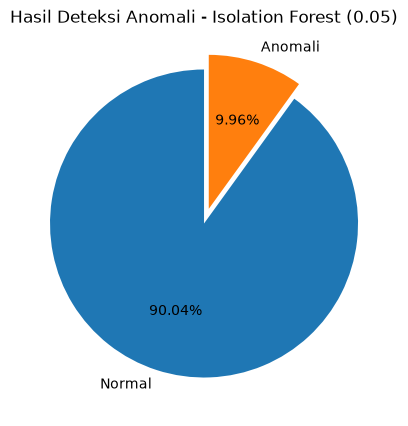

In [61]:
import matplotlib.pyplot as plt

jumlah_data = [
    jumlah_normal_05,
    jumlah_anomali_05
]

label_data = [
    "Normal",
    "Anomali"
]

plt.figure(figsize=(7, 5))

plt.pie(
    jumlah_data,
    labels=label_data,
    autopct="%1.2f%%",
    startangle=90,
    explode=(0, 0.1)
)

plt.title("Hasil Deteksi Anomali - Isolation Forest (0.05)")
plt.show()

In [62]:
import os
import joblib

# Membuat folder penyimpanan
os.makedirs("../models", exist_ok=True)
os.makedirs("../outputs", exist_ok=True)

# Menyimpan model Isolation Forest
joblib.dump(
    model_05,
    "../models/isolation_forest_05.joblib"
)

# Menambahkan waktu pencatatan pada hasil deteksi
hasil_simpan = hasil_05.copy()

hasil_simpan["waktu_tercatat"] = df.loc[
    hasil_simpan.index,
    "waktu_tercatat"
]

# Menyimpan hasil deteksi ke CSV
hasil_simpan.to_csv(
    "../outputs/hasil_deteksi_05.csv",
    index=False
)

print("PENYIMPANAN BERHASIL")
print("----------------------------")
print("Model: models/isolation_forest_05.joblib")
print("Hasil: outputs/hasil_deteksi_05.csv")

PENYIMPANAN BERHASIL
----------------------------
Model: models/isolation_forest_05.joblib
Hasil: outputs/hasil_deteksi_05.csv


In [63]:
import joblib
import os

# Memuat model yang sudah disimpan
model_tersimpan = joblib.load(
    "../models/isolation_forest_05.joblib"
)

# Menguji prediksi menggunakan model tersimpan
prediksi_ulang = model_tersimpan.predict(X_test)

# Membandingkan hasil prediksi
jumlah_sama = (prediksi_ulang == prediksi_05).sum()

print("PENGUJIAN MODEL TERSIMPAN")
print("----------------------------")
print("Model berhasil dimuat:", model_tersimpan is not None)
print("Jumlah data pengujian:", len(X_test))
print("Prediksi sama:", jumlah_sama)
print("Persentase kesamaan:",
      f"{jumlah_sama / len(X_test) * 100:.2f}%")

PENGUJIAN MODEL TERSIMPAN
----------------------------
Model berhasil dimuat: True
Jumlah data pengujian: 7707
Prediksi sama: 7707
Persentase kesamaan: 100.00%


In [64]:
# Membuat ringkasan hasil deteksi
ringkasan = pd.DataFrame({
    "Kategori": ["Normal", "Anomali"],
    "Jumlah Data": [
        jumlah_normal_05,
        jumlah_anomali_05
    ],
    "Persentase": [
        jumlah_normal_05 / len(X_test) * 100,
        jumlah_anomali_05 / len(X_test) * 100
    ]
})

display(ringkasan.round(2))

# Menyimpan ringkasan
ringkasan.to_csv(
    "../outputs/ringkasan_deteksi.csv",
    index=False
)

print("Ringkasan berhasil disimpan!")

,Kategori,Jumlah Data,Persentase
0,Normal,6939,90.04
1,Anomali,768,9.96


Ringkasan berhasil disimpan!


In [65]:
import os

daftar_file = [
    "../models/isolation_forest_05.joblib",
    "../outputs/hasil_deteksi_05.csv",
    "../outputs/ringkasan_deteksi.csv"
]

print("PEMERIKSAAN FILE PROYEK")
print("----------------------------")

for file in daftar_file:
    if os.path.exists(file):
        print("[OK]", file)
    else:
        print("[BELUM ADA]", file)

PEMERIKSAAN FILE PROYEK
----------------------------
[OK] ../models/isolation_forest_05.joblib
[OK] ../outputs/hasil_deteksi_05.csv
[OK] ../outputs/ringkasan_deteksi.csv


In [66]:

import pandas as pd

# Membaca dataset
df = pd.read_csv("../dataset/DATA SENSOR.csv")

# Mengubah waktu menjadi datetime
df["waktu_tercatat"] = pd.to_datetime(df["waktu_tercatat"])

# Mengurutkan berdasarkan waktu
df = df.sort_values("waktu_tercatat").reset_index(drop=True)

# Menghitung jeda antar data
df["gap_sec"] = df["waktu_tercatat"].diff().dt.total_seconds()

# Membentuk sesi sementara berdasarkan jeda lebih dari 1 jam
df["session_id"] = (
    df["gap_sec"].isna() |
    (df["gap_sec"] > 3600)
).cumsum()

# Membuat ringkasan sesi
ringkasan = df.groupby("session_id").agg(
    waktu_mulai=("waktu_tercatat", "min"),
    waktu_selesai=("waktu_tercatat", "max"),
    jumlah_data=("waktu_tercatat", "count"),
    jeda_maksimum_detik=("gap_sec", "max")
).reset_index()

ringkasan["durasi_jam"] = (
    (ringkasan["waktu_selesai"] -
     ringkasan["waktu_mulai"]).dt.total_seconds() / 3600
).round(2)

print("JUMLAH SESI SEMENTARA:", len(ringkasan))
display(ringkasan)


JUMLAH SESI SEMENTARA: 52


,session_id,waktu_mulai,waktu_selesai,jumlah_data,jeda_maksimum_detik,durasi_jam
0,1,2026-01-19 11:40:18,2026-01-20 08:59:59,1136,3369.0,21.33
1,2,2026-01-26 09:56:12,2026-01-27 10:04:04,1289,521773.0,24.13
2,3,2026-02-12 10:36:31,2026-02-12 16:33:43,282,1384347.0,5.95
3,4,2026-02-12 18:25:52,2026-02-13 09:30:16,746,6729.0,15.07
4,5,2026-03-26 09:46:52,2026-03-27 09:20:16,1211,3543396.0,23.56
5,6,2026-04-13 10:53:24,2026-04-14 10:01:43,1191,1474388.0,23.14
6,7,2026-04-21 10:11:05,2026-04-22 09:59:39,1065,605362.0,23.81
7,8,2026-04-23 10:04:03,2026-04-24 09:49:29,1046,86664.0,23.76
8,9,2026-04-27 10:08:28,2026-04-28 09:48:27,1143,260339.0,23.67
9,10,2026-05-05 09:24:27,2026-05-06 10:05:41,1144,603360.0,24.69


In [67]:

# Menghitung jeda hanya di dalam masing-masing sesi

df["gap_dalam_sesi"] = (
    df.groupby("session_id")["waktu_tercatat"]
      .diff()
      .dt.total_seconds()
)

ringkasan_baru = df.groupby("session_id").agg(
    waktu_mulai=("waktu_tercatat", "min"),
    waktu_selesai=("waktu_tercatat", "max"),
    jumlah_data=("waktu_tercatat", "count"),
    jeda_maksimum=("gap_dalam_sesi", "max")
).reset_index()

ringkasan_baru["durasi_jam"] = (
    (ringkasan_baru["waktu_selesai"] -
     ringkasan_baru["waktu_mulai"]).dt.total_seconds() / 3600
).round(2)

ringkasan_baru["jeda_maksimum_menit"] = (
    ringkasan_baru["jeda_maksimum"] / 60
).round(2)

display(ringkasan_baru)


,session_id,waktu_mulai,waktu_selesai,jumlah_data,jeda_maksimum,durasi_jam,jeda_maksimum_menit
0,1,2026-01-19 11:40:18,2026-01-20 08:59:59,1136,3369.0,21.33,56.15
1,2,2026-01-26 09:56:12,2026-01-27 10:04:04,1289,295.0,24.13,4.92
2,3,2026-02-12 10:36:31,2026-02-12 16:33:43,282,526.0,5.95,8.77
3,4,2026-02-12 18:25:52,2026-02-13 09:30:16,746,305.0,15.07,5.08
4,5,2026-03-26 09:46:52,2026-03-27 09:20:16,1211,373.0,23.56,6.22
5,6,2026-04-13 10:53:24,2026-04-14 10:01:43,1191,218.0,23.14,3.63
6,7,2026-04-21 10:11:05,2026-04-22 09:59:39,1065,372.0,23.81,6.20
7,8,2026-04-23 10:04:03,2026-04-24 09:49:29,1046,450.0,23.76,7.50
8,9,2026-04-27 10:08:28,2026-04-28 09:48:27,1143,449.0,23.67,7.48
9,10,2026-05-05 09:24:27,2026-05-06 10:05:41,1144,381.0,24.69,6.35


In [68]:
# Menghitung jeda antara sesi yang berurutan

batas_sesi = ringkasan_baru.copy()

batas_sesi["sesi_sebelumnya"] = batas_sesi["session_id"].shift(1)
batas_sesi["selesai_sebelumnya"] = batas_sesi["waktu_selesai"].shift(1)

batas_sesi["jeda_antar_sesi_menit"] = (
    batas_sesi["waktu_mulai"] -
    batas_sesi["selesai_sebelumnya"]
).dt.total_seconds() / 60

batas_sesi["rentang_jika_digabung_jam"] = (
    batas_sesi["waktu_selesai"] -
    batas_sesi["selesai_sebelumnya"]
).dt.total_seconds() / 3600

display(
    batas_sesi[
        [
            "sesi_sebelumnya",
            "session_id",
            "selesai_sebelumnya",
            "waktu_mulai",
            "jeda_antar_sesi_menit",
            "rentang_jika_digabung_jam"
        ]
    ].round(2)
)

C:\Users\user\AppData\Local\Temp\ipykernel_14000\2677742119.py:28: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,sesi_sebelumnya,session_id,selesai_sebelumnya,waktu_mulai,jeda_antar_sesi_menit,rentang_jika_digabung_jam
0,NaN,1,NaT,2026-01-19 11:40:18,NaN,NaN
1,1.0,2,2026-01-20 08:59:59,2026-01-26 09:56:12,8696.22,169.07
2,2.0,3,2026-01-27 10:04:04,2026-02-12 10:36:31,23072.45,390.49
3,3.0,4,2026-02-12 16:33:43,2026-02-12 18:25:52,112.15,16.94
4,4.0,5,2026-02-13 09:30:16,2026-03-26 09:46:52,59056.60,1007.83
5,5.0,6,2026-03-27 09:20:16,2026-04-13 10:53:24,24573.13,432.69
6,6.0,7,2026-04-14 10:01:43,2026-04-21 10:11:05,10089.37,191.97
7,7.0,8,2026-04-22 09:59:39,2026-04-23 10:04:03,1444.40,47.83
8,8.0,9,2026-04-24 09:49:29,2026-04-27 10:08:28,4338.98,95.98
9,9.0,10,2026-04-28 09:48:27,2026-05-05 09:24:27,10056.00,192.29


In [69]:
# Ringkasan karakteristik data setiap sesi

ringkasan_sensor = df.groupby("session_id").agg(
    jumlah_data=("id_monitoring_udara", "count"),

    suhu_rata=("suhu", "mean"),
    kelembaban_rata=("kelembaban", "mean"),

    pm10_rata=("pm10", "mean"),
    pm25_rata=("pm25", "mean"),

    barometer_rata=("barometer", "mean"),
    tvoc_rata=("tvoc", "mean"),

    tvoc_unik=("tvoc", "nunique"),
    pm10_unik=("pm10", "nunique"),
    pm25_unik=("pm25", "nunique")
).reset_index()

ringkasan_sensor = ringkasan_sensor.round(2)

display(ringkasan_sensor)

,session_id,jumlah_data,suhu_rata,kelembaban_rata,pm10_rata,pm25_rata,barometer_rata,tvoc_rata,tvoc_unik,pm10_unik,pm25_unik
0,1,1136,25.05,62.36,27.77,13.62,701.51,736.14,5,69,36
1,2,1289,25.16,60.34,25.70,12.41,703.27,715.69,5,62,30
2,3,282,29.64,50.97,12.79,6.36,698.26,775.71,4,40,21
3,4,746,22.55,72.85,18.64,8.92,700.04,753.94,4,65,34
4,5,1211,25.99,63.12,25.42,12.35,701.52,736.30,5,67,33
5,6,1191,25.74,65.62,38.55,18.24,698.14,776.69,6,65,31
6,7,1065,27.36,61.12,29.52,14.23,701.45,737.45,6,57,27
7,8,1046,27.75,56.72,42.75,20.29,700.44,748.86,6,99,61
8,9,1143,27.80,61.92,35.74,16.97,699.04,765.81,5,66,33
9,10,1144,26.87,63.68,30.92,14.80,702.42,726.10,5,70,36


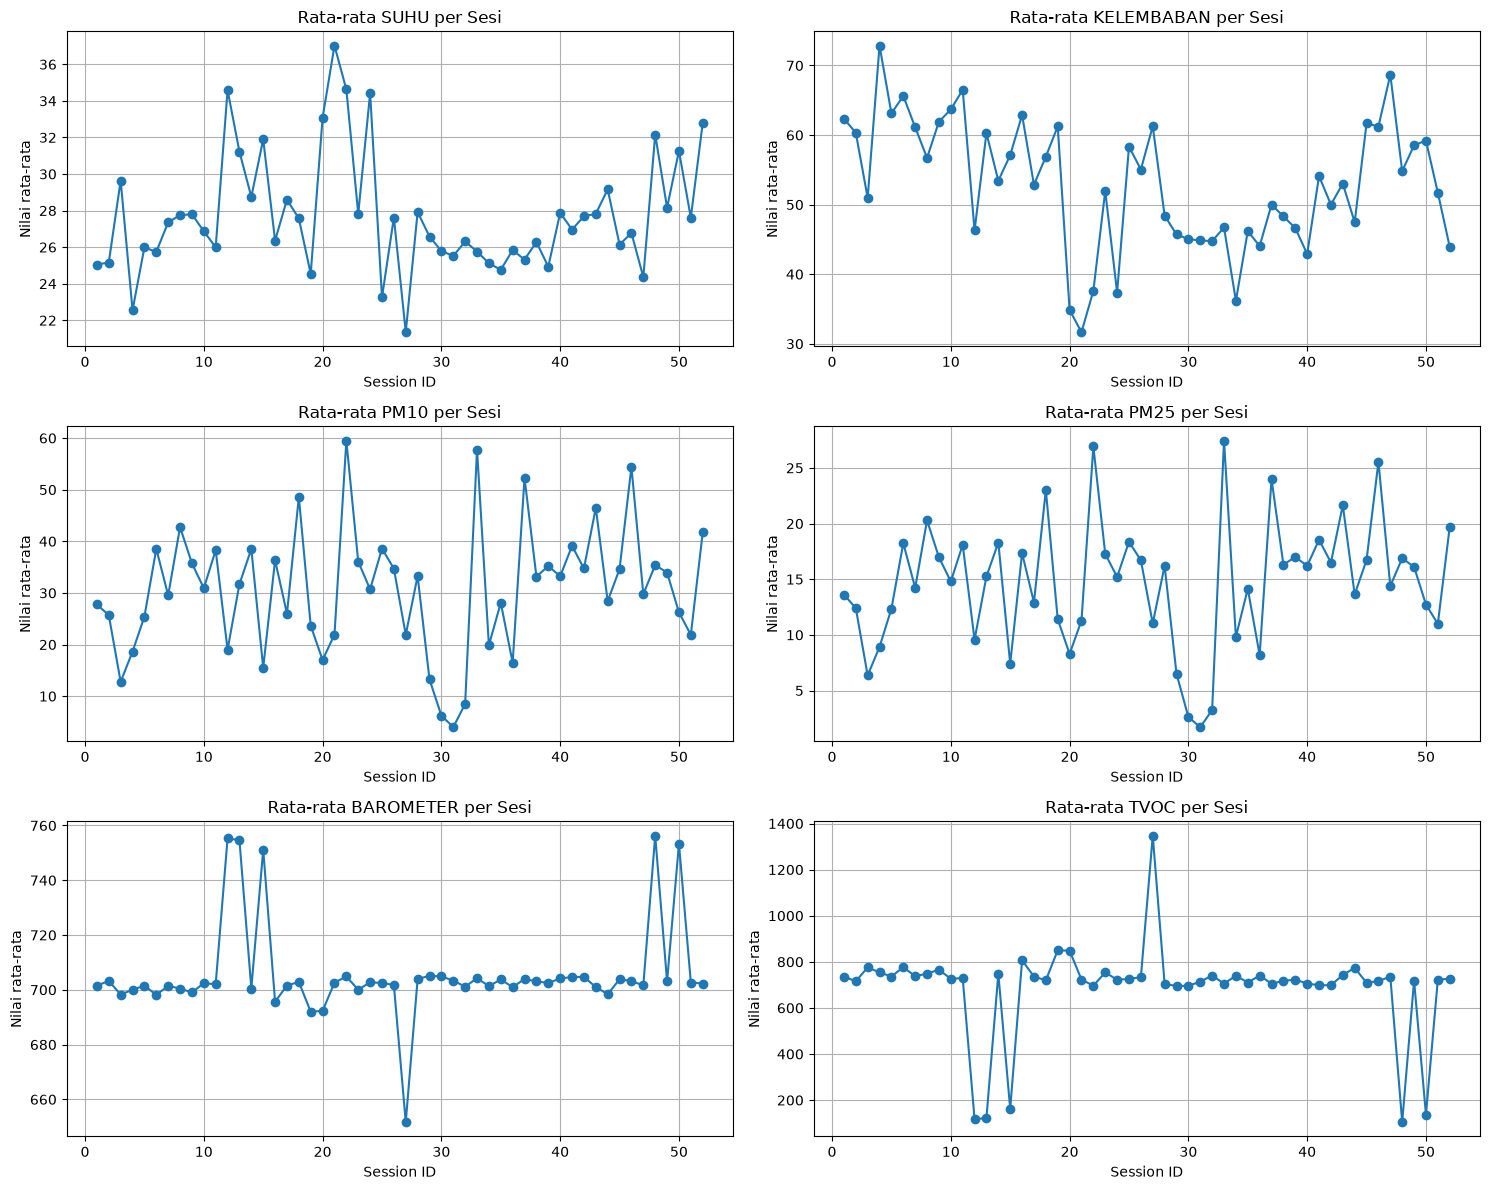

In [70]:
import matplotlib.pyplot as plt

# Visualisasi rata-rata sensor setiap sesi

kolom_sensor = [
    "suhu",
    "kelembaban",
    "pm10",
    "pm25",
    "barometer",
    "tvoc"
]

fig, axes = plt.subplots(3, 2, figsize=(15, 12))

for kolom, ax in zip(kolom_sensor, axes.flatten()):
    ax.plot(
        ringkasan_sensor["session_id"],
        ringkasan_sensor[f"{kolom}_rata"],
        marker="o"
    )

    ax.set_title(f"Rata-rata {kolom.upper()} per Sesi")
    ax.set_xlabel("Session ID")
    ax.set_ylabel("Nilai rata-rata")
    ax.grid(True)

plt.tight_layout()
plt.show()


In [71]:
# Korelasi Barometer dan TVOC per sesi

hasil_korelasi = df.groupby("session_id").apply(
    lambda g: g["barometer"].corr(g["tvoc"]),
    include_groups=False
).reset_index(name="korelasi_barometer_tvoc")

display(hasil_korelasi.round(4))

,session_id,korelasi_barometer_tvoc
0,1,-0.9748
1,2,-0.9623
2,3,-0.9704
3,4,-0.9501
4,5,-0.9644
5,6,-0.9723
6,7,-0.9856
7,8,-0.9727
8,9,-0.9791
9,10,-0.9724


In [72]:
hasil_korelasi_pm = df.groupby("session_id").apply(
    lambda g: g["pm10"].corr(g["pm25"]),
    include_groups=False
).reset_index(name="korelasi_pm10_pm25")

display(hasil_korelasi_pm.round(4))

,session_id,korelasi_pm10_pm25
0,1,0.9780
1,2,0.9846
2,3,0.9895
3,4,0.9883
4,5,0.9810
5,6,0.9920
6,7,0.9859
7,8,0.9900
8,9,0.9923
9,10,0.9891


In [73]:
# Ringkasan variasi sensor setiap sesi

variasi_sesi = df.groupby("session_id").agg(
    jumlah_data=("id_monitoring_udara", "count"),

    std_barometer=("barometer", "std"),
    std_tvoc=("tvoc", "std"),

    std_pm10=("pm10", "std"),
    std_pm25=("pm25", "std"),

    min_barometer=("barometer", "min"),
    max_barometer=("barometer", "max"),

    min_tvoc=("tvoc", "min"),
    max_tvoc=("tvoc", "max")
).reset_index()

display(variasi_sesi.round(2))

,session_id,jumlah_data,std_barometer,std_tvoc,std_pm10,std_pm25,min_barometer,max_barometer,min_tvoc,max_tvoc
0,1,1136,1.00,12.18,11.09,5.27,699.32,702.81,722.78,758.50
1,2,1289,0.81,9.13,12.46,5.83,701.55,704.56,696.08,731.70
2,3,282,0.75,9.65,10.70,5.66,697.46,699.88,758.50,785.37
3,4,746,0.64,8.42,14.94,7.40,699.07,701.27,740.63,767.45
4,5,1211,0.79,9.86,11.49,5.40,699.69,702.63,722.78,758.50
5,6,1191,0.88,10.89,16.12,7.13,696.08,699.51,758.50,803.32
6,7,1065,1.11,13.09,12.50,5.94,699.22,702.98,722.78,767.45
7,8,1046,0.98,11.75,19.00,9.29,698.52,701.71,731.70,776.40
8,9,1143,1.01,12.22,15.73,7.28,697.27,700.75,749.56,785.37
9,10,1144,0.88,10.52,14.64,6.91,700.18,703.68,713.87,749.56


In [74]:
# Menghitung rata-rata dan standar deviasi setiap sensor
# berdasarkan sesi

fitur_sesi = df.groupby("session_id").agg(
    suhu_mean=("suhu", "mean"),
    suhu_std=("suhu", "std"),

    kelembaban_mean=("kelembaban", "mean"),
    kelembaban_std=("kelembaban", "std"),

    pm10_mean=("pm10", "mean"),
    pm10_std=("pm10", "std"),

    pm25_mean=("pm25", "mean"),
    pm25_std=("pm25", "std"),

    barometer_mean=("barometer", "mean"),
    barometer_std=("barometer", "std"),

    tvoc_mean=("tvoc", "mean"),
    tvoc_std=("tvoc", "std")
).reset_index()

display(fitur_sesi.round(2))

,session_id,suhu_mean,suhu_std,kelembaban_mean,kelembaban_std,pm10_mean,pm10_std,pm25_mean,pm25_std,barometer_mean,barometer_std,tvoc_mean,tvoc_std
0,1,25.05,2.33,62.36,7.66,27.77,11.09,13.62,5.27,701.51,1.00,736.14,12.18
1,2,25.16,2.77,60.34,7.29,25.70,12.46,12.41,5.83,703.27,0.81,715.69,9.13
2,3,29.64,2.25,50.97,5.71,12.79,10.70,6.36,5.66,698.26,0.75,775.71,9.65
3,4,22.55,0.90,72.85,2.82,18.64,14.94,8.92,7.40,700.04,0.64,753.94,8.42
4,5,25.99,2.55,63.12,8.53,25.42,11.49,12.35,5.40,701.52,0.79,736.30,9.86
5,6,25.74,3.58,65.62,10.32,38.55,16.12,18.24,7.13,698.14,0.88,776.69,10.89
6,7,27.36,4.46,61.12,14.49,29.52,12.50,14.23,5.94,701.45,1.11,737.45,13.09
7,8,27.75,3.81,56.72,9.60,42.75,19.00,20.29,9.29,700.44,0.98,748.86,11.75
8,9,27.80,4.13,61.92,10.98,35.74,15.73,16.97,7.28,699.04,1.01,765.81,12.22
9,10,26.87,3.18,63.68,10.38,30.92,14.64,14.80,6.91,702.42,0.88,726.10,10.52


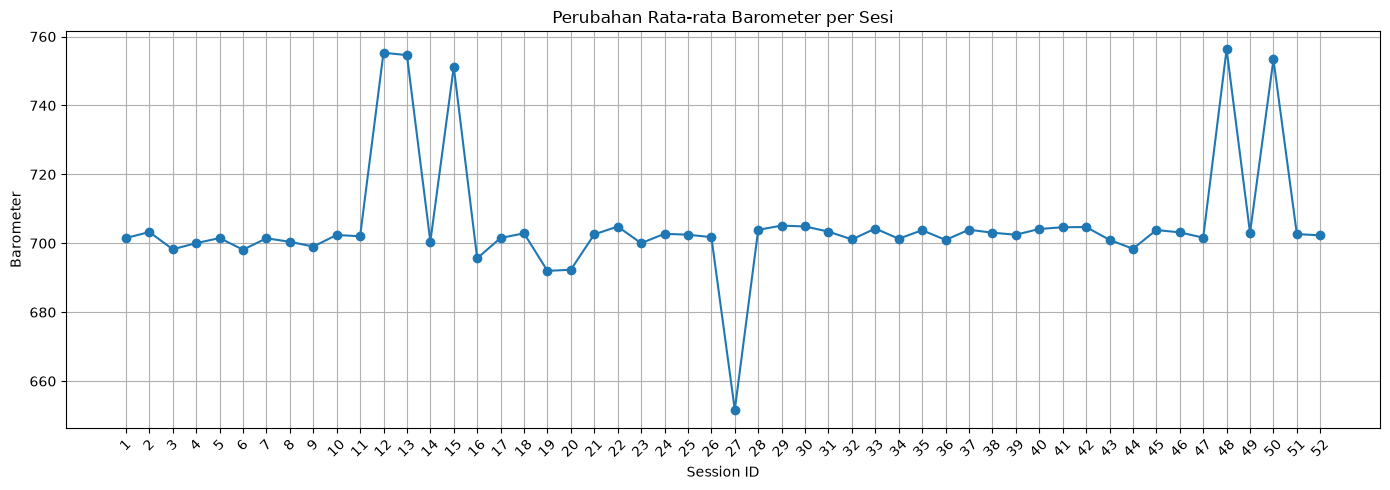

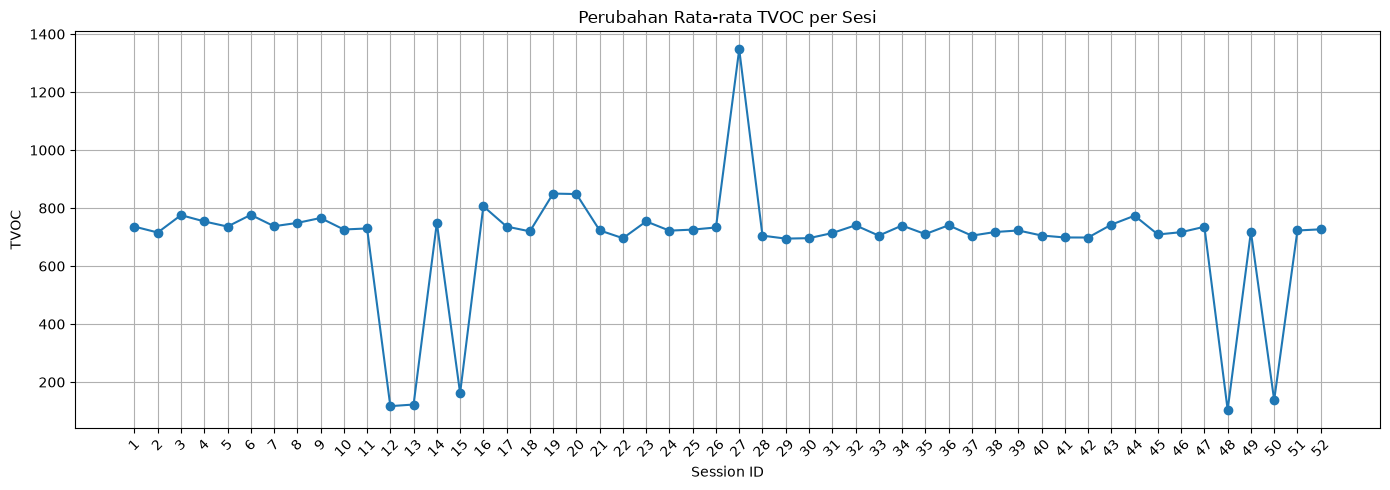

In [75]:
import matplotlib.pyplot as plt

# Grafik rata-rata Barometer
plt.figure(figsize=(14, 5))
plt.plot(
    fitur_sesi["session_id"],
    fitur_sesi["barometer_mean"],
    marker="o"
)
plt.title("Perubahan Rata-rata Barometer per Sesi")
plt.xlabel("Session ID")
plt.ylabel("Barometer")
plt.xticks(fitur_sesi["session_id"], rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


# Grafik rata-rata TVOC
plt.figure(figsize=(14, 5))
plt.plot(
    fitur_sesi["session_id"],
    fitur_sesi["tvoc_mean"],
    marker="o"
)
plt.title("Perubahan Rata-rata TVOC per Sesi")
plt.xlabel("Session ID")
plt.ylabel("TVOC")
plt.xticks(fitur_sesi["session_id"], rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

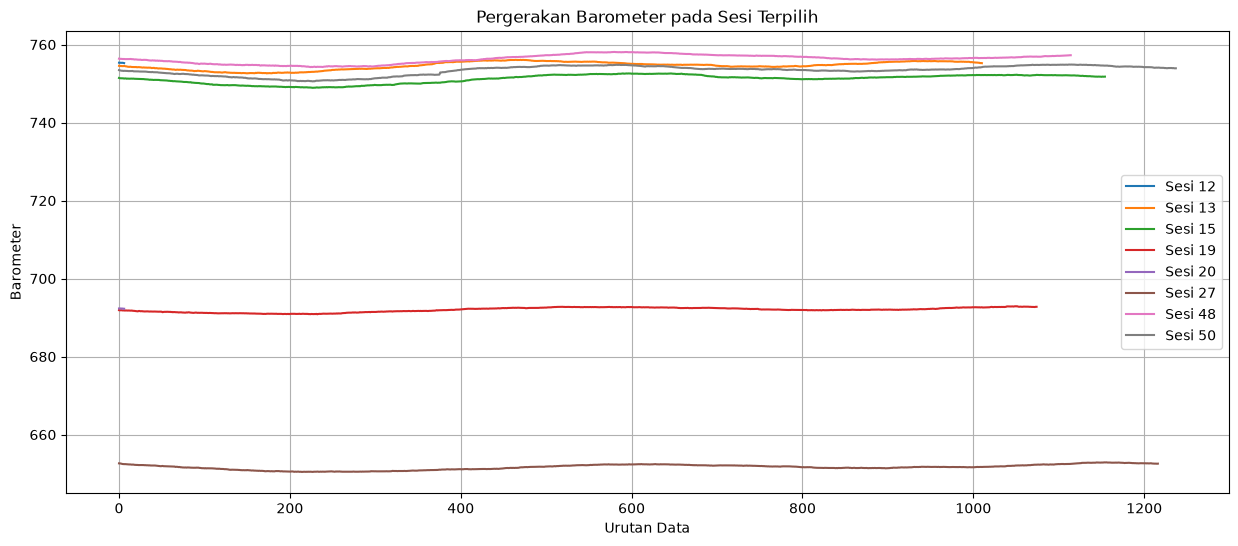

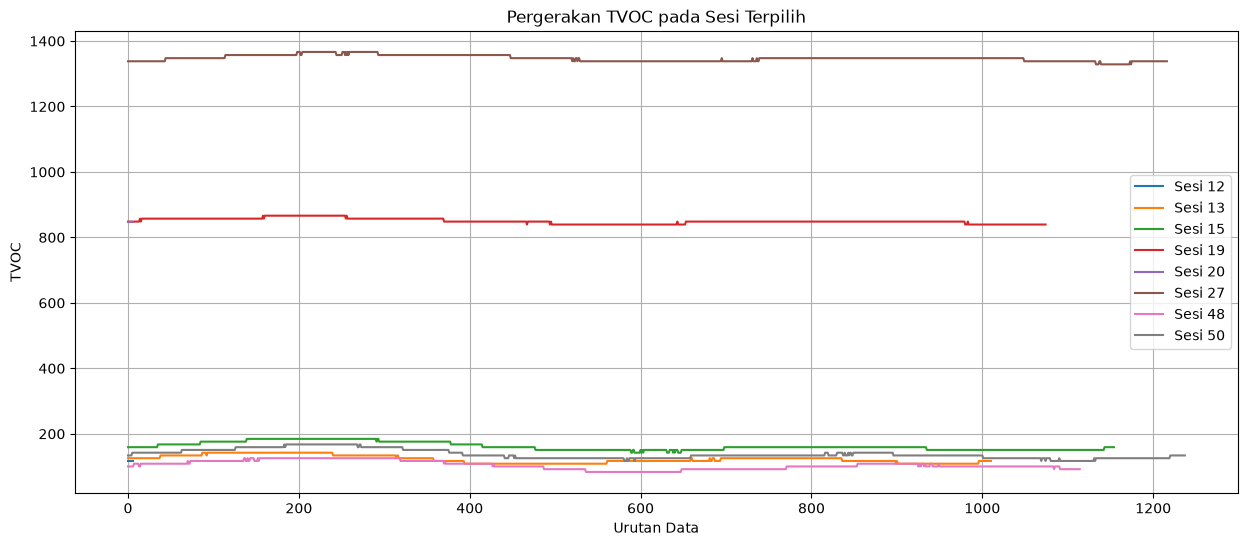

In [76]:
# Ambil sesi yang memiliki perubahan karakteristik mencolok
sesi_pemeriksaan = [12, 13, 15, 19, 20, 27, 48, 50]

df_pemeriksaan = df[df["session_id"].isin(sesi_pemeriksaan)].copy()

# Visualisasi Barometer
plt.figure(figsize=(15, 6))

for sid in sesi_pemeriksaan:
    data = df_pemeriksaan[df_pemeriksaan["session_id"] == sid]

    plt.plot(
        range(len(data)),
        data["barometer"].values,
        label=f"Sesi {sid}"
    )

plt.title("Pergerakan Barometer pada Sesi Terpilih")
plt.xlabel("Urutan Data")
plt.ylabel("Barometer")
plt.legend()
plt.grid(True)
plt.show()


# Visualisasi TVOC
plt.figure(figsize=(15, 6))

for sid in sesi_pemeriksaan:
    data = df_pemeriksaan[df_pemeriksaan["session_id"] == sid]

    plt.plot(
        range(len(data)),
        data["tvoc"].values,
        label=f"Sesi {sid}"
    )

plt.title("Pergerakan TVOC pada Sesi Terpilih")
plt.xlabel("Urutan Data")
plt.ylabel("TVOC")
plt.legend()
plt.grid(True)
plt.show()

In [77]:
sesi_pemeriksaan = [13, 15, 19, 27, 48, 50]

hasil_posisi = []

for sid in sesi_pemeriksaan:
    data = (
        df[df["session_id"] == sid]
        .sort_values("waktu_tercatat")
        .reset_index(drop=True)
    )

    n = len(data)

    bagian = {
        "awal": data.iloc[:max(1, n // 3)],
        "tengah": data.iloc[n // 3:2 * n // 3],
        "akhir": data.iloc[2 * n // 3:]
    }

    for nama_bagian, potongan in bagian.items():
        hasil_posisi.append({
            "session_id": sid,
            "bagian": nama_bagian,
            "barometer_mean": potongan["barometer"].mean(),
            "tvoc_mean": potongan["tvoc"].mean(),
            "pm10_mean": potongan["pm10"].mean(),
            "pm25_mean": potongan["pm25"].mean()
        })

hasil_posisi = pd.DataFrame(hasil_posisi)

display(hasil_posisi.round(2))

,session_id,bagian,barometer_mean,tvoc_mean,pm10_mean,pm25_mean
0,13,awal,753.42,136.16,20.06,9.84
1,13,tengah,755.40,113.42,36.99,17.83
2,13,akhir,755.01,118.26,38.08,18.09
3,15,awal,749.84,176.62,13.56,6.31
4,15,tengah,751.90,154.50,18.19,8.81
5,15,akhir,751.78,154.57,14.69,7.12
6,19,awal,691.29,859.44,14.53,6.97
7,19,tengah,692.46,844.66,31.54,15.30
8,19,akhir,692.25,845.98,24.95,11.94
9,27,awal,651.04,1355.39,20.32,10.36


In [78]:
# Menghitung perubahan persentase awal ke akhir

kolom_sensor = [
    "barometer",
    "tvoc",
    "pm10",
    "pm25"
]

hasil_perubahan = []

for sid, data in df.groupby("session_id"):
    data = data.sort_values("waktu_tercatat").reset_index(drop=True)

    n = len(data)
    awal = data.iloc[:max(1, n // 3)]
    akhir = data.iloc[2 * n // 3:]

    hasil = {"session_id": sid}

    for sensor in kolom_sensor:
        nilai_awal = awal[sensor].mean()
        nilai_akhir = akhir[sensor].mean()

        perubahan = (
            (nilai_akhir - nilai_awal) / abs(nilai_awal) * 100
            if nilai_awal != 0 else None
        )

        hasil[f"{sensor}_perubahan_pct"] = perubahan

    hasil_perubahan.append(hasil)

hasil_perubahan = pd.DataFrame(hasil_perubahan)

display(hasil_perubahan.round(2))

,session_id,barometer_perubahan_pct,tvoc_perubahan_pct,pm10_perubahan_pct,pm25_perubahan_pct
0,1,0.22,-2.56,50.74,50.00
1,2,0.17,-1.68,100.64,106.10
2,3,-0.23,2.73,-35.31,-35.77
3,4,-0.11,1.22,120.69,118.60
4,5,0.17,-2.00,92.36,92.48
5,6,0.19,-1.96,129.52,115.79
6,7,0.22,-2.40,74.81,75.16
7,8,0.22,-2.41,41.55,41.08
8,9,0.20,-2.25,189.91,171.81
9,10,0.13,-1.31,23.28,22.99


In [7]:
import os

print("Lokasi kerja saat ini:")
print(os.getcwd())

print("\nIsi folder saat ini:")
print(os.listdir())

Lokasi kerja saat ini:
C:\AI-Anomaly-Detection\notebooks

Isi folder saat ini:
['.ipynb_checkpoints', '01_analisis_dataset.ipynb']


In [9]:
import os

for root, dirs, files in os.walk(".."):
    dirs[:] = [d for d in dirs if d not in [".venv", "__pycache__", ".git"]]

    for file in files:
        if file.lower() == "data_sensor.csv":
            print("Dataset ditemukan:", os.path.join(root, file))

In [10]:
import os

folder_proyek = r"C:\AI-Anomaly-Detection"

for root, dirs, files in os.walk(folder_proyek):
    dirs[:] = [d for d in dirs if d not in [".venv", "__pycache__", ".git"]]

    for file in files:
        if file.lower().endswith(".csv"):
            print(os.path.join(root, file))

C:\AI-Anomaly-Detection\dataset\DATA SENSOR.csv
C:\AI-Anomaly-Detection\outputs\hasil_deteksi_05.csv
C:\AI-Anomaly-Detection\outputs\ringkasan_deteksi.csv


In [11]:
import pandas as pd

df = pd.read_csv(r"C:\AI-Anomaly-Detection\dataset\DATA SENSOR.csv")

print("Dataset berhasil dimuat!")
print("Jumlah data:", len(df))
print("Nama kolom:")
print(df.columns.tolist())

display(df.head())

Dataset berhasil dimuat!
Jumlah data: 38531
Nama kolom:
['id_monitoring_udara', 'suhu', 'kelembaban', 'pm10', 'pm25', 'barometer', 'tvoc', 'waktu_tercatat']


,id_monitoring_udara,suhu,kelembaban,pm10,pm25,barometer,tvoc,waktu_tercatat
0,164460,29.39,46,8.0,3.0,701.29,740.63,2026-01-19 11:40:18
1,164461,29.29,46,5.0,2.0,701.27,740.63,2026-01-19 11:41:22
2,164462,29.39,45,1.0,0.0,701.26,740.63,2026-01-19 11:42:27
3,164463,29.39,45,4.0,1.0,701.26,740.63,2026-01-19 11:43:31
4,164464,29.29,44,0.0,0.0,701.27,740.63,2026-01-19 11:44:36


In [16]:
kolom_sensor = [
    "barometer",
    "tvoc",
    "pm10",
    "pm25"
]

hasil_perubahan = []

for sid, data in df.groupby("session_id"):
    data = data.sort_values("waktu_tercatat").reset_index(drop=True)

    n = len(data)
    awal = data.iloc[:max(1, n // 3)]
    akhir = data.iloc[2 * n // 3:]

    hasil = {"session_id": sid}

    for sensor in kolom_sensor:
        nilai_awal = awal[sensor].mean()
        nilai_akhir = akhir[sensor].mean()

        perubahan = (
            (nilai_akhir - nilai_awal) / abs(nilai_awal) * 100
            if nilai_awal != 0 else None
        )

        hasil[f"{sensor}_perubahan_pct"] = perubahan

    hasil_perubahan.append(hasil)

hasil_perubahan = pd.DataFrame(hasil_perubahan)

display(hasil_perubahan.round(2))

,session_id,barometer_perubahan_pct,tvoc_perubahan_pct,pm10_perubahan_pct,pm25_perubahan_pct
0,1,0.22,-2.56,50.74,50.00
1,2,0.17,-1.68,100.64,106.10
2,3,-0.23,2.73,-35.31,-35.77
3,4,-0.11,1.22,120.69,118.60
4,5,0.17,-2.00,92.36,92.48
5,6,0.19,-1.96,129.52,115.79
6,7,0.22,-2.40,74.81,75.16
7,8,0.22,-2.41,41.55,41.08
8,9,0.20,-2.25,189.91,171.81
9,10,0.13,-1.31,23.28,22.99


In [13]:
print(df.columns.tolist())

['id_monitoring_udara', 'suhu', 'kelembaban', 'pm10', 'pm25', 'barometer', 'tvoc', 'waktu_tercatat']


In [14]:
df["waktu_tercatat"] = pd.to_datetime(df["waktu_tercatat"])

df = df.sort_values("waktu_tercatat").reset_index(drop=True)

df["gap_sec"] = df["waktu_tercatat"].diff().dt.total_seconds()

df["session_id"] = (
    df["gap_sec"].isna() | (df["gap_sec"] > 3600)
).cumsum()

print("Jumlah data:", len(df))
print("Jumlah sesi:", df["session_id"].nunique())

Jumlah data: 38531
Jumlah sesi: 52


In [17]:
# Tambahkan jumlah data pada setiap sesi
jumlah_data_sesi = (
    df.groupby("session_id")
    .size()
    .reset_index(name="jumlah_data")
)

hasil_validasi = hasil_perubahan.merge(
    jumlah_data_sesi,
    on="session_id"
)

# Ambil sesi utama (minimal 1.000 data)
sesi_utama = hasil_validasi[
    hasil_validasi["jumlah_data"] >= 1000
].copy()

# Urutkan berdasarkan perubahan PM terbesar
sesi_utama["perubahan_pm_maks_pct"] = (
    sesi_utama[
        ["pm10_perubahan_pct", "pm25_perubahan_pct"]
    ].abs().max(axis=1)
)

sesi_utama = sesi_utama.sort_values(
    "perubahan_pm_maks_pct",
    ascending=False
)

display(sesi_utama.round(2))

,session_id,barometer_perubahan_pct,tvoc_perubahan_pct,pm10_perubahan_pct,pm25_perubahan_pct,jumlah_data,perubahan_pm_maks_pct
8,9,0.20,-2.25,189.91,171.81,1143,189.91
13,14,0.18,-1.98,186.75,180.28,1109,186.75
41,42,0.15,-1.72,177.62,155.08,1150,177.62
39,40,0.27,-3.09,141.16,122.79,1008,141.16
5,6,0.19,-1.96,129.52,115.79,1191,129.52
47,48,0.21,-15.34,128.48,108.85,1115,128.48
43,44,0.18,-1.82,120.92,118.62,1287,120.92
10,11,0.13,-1.71,108.66,93.32,1131,108.66
1,2,0.17,-1.68,100.64,106.10,1289,106.10
4,5,0.17,-2.00,92.36,92.48,1211,92.48


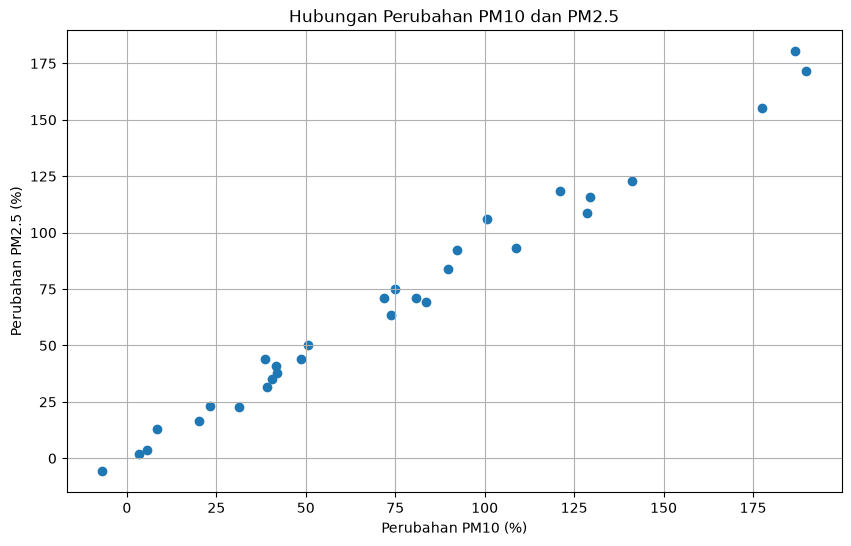

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    sesi_utama["pm10_perubahan_pct"],
    sesi_utama["pm25_perubahan_pct"]
)

plt.xlabel("Perubahan PM10 (%)")
plt.ylabel("Perubahan PM2.5 (%)")
plt.title("Hubungan Perubahan PM10 dan PM2.5")
plt.grid(True)

plt.show()

In [19]:
korelasi_perubahan = sesi_utama[
    ["pm10_perubahan_pct", "pm25_perubahan_pct"]
].corr(method="pearson")

display(korelasi_perubahan.round(4))

,pm10_perubahan_pct,pm25_perubahan_pct
pm10_perubahan_pct,1.0000,0.9932
pm25_perubahan_pct,0.9932,1.0000


In [20]:
kolom_sensor = ["pm10", "pm25"]

hasil_delta = []

for sid, data in df.groupby("session_id"):
    data = data.sort_values("waktu_tercatat").reset_index(drop=True)

    n = len(data)
    awal = data.iloc[:max(1, n // 3)]
    akhir = data.iloc[2 * n // 3:]

    hasil = {"session_id": sid}

    for sensor in kolom_sensor:
        nilai_awal = awal[sensor].mean()
        nilai_akhir = akhir[sensor].mean()

        hasil[f"{sensor}_awal"] = nilai_awal
        hasil[f"{sensor}_akhir"] = nilai_akhir
        hasil[f"{sensor}_delta"] = nilai_akhir - nilai_awal

    hasil_delta.append(hasil)

hasil_delta = pd.DataFrame(hasil_delta)

sesi_utama_delta = hasil_delta[
    hasil_delta["session_id"].isin(
        sesi_utama["session_id"]
    )
]

display(sesi_utama_delta.round(2))

,session_id,pm10_awal,pm10_akhir,pm10_delta,pm25_awal,pm25_akhir,pm25_delta
0,1,22.44,33.82,11.38,10.97,16.46,5.49
1,2,14.06,28.21,14.15,6.70,13.81,7.11
4,5,17.01,32.72,15.71,8.21,15.81,7.60
5,6,20.22,46.41,26.19,10.10,21.80,11.70
6,7,19.58,34.22,14.65,9.40,16.46,7.06
7,8,30.10,42.60,12.51,14.40,20.32,5.92
8,9,16.30,47.26,30.96,8.18,22.22,14.05
9,10,31.44,38.76,7.32,15.06,18.52,3.46
10,11,22.42,46.77,24.36,11.24,21.73,10.49
12,13,20.06,38.08,18.03,9.84,18.09,8.26


In [21]:
korelasi_delta = sesi_utama_delta[
    ["pm10_delta", "pm25_delta"]
].corr(method="pearson")

display(korelasi_delta.round(4))

,pm10_delta,pm25_delta
pm10_delta,1.0000,0.9945
pm25_delta,0.9945,1.0000


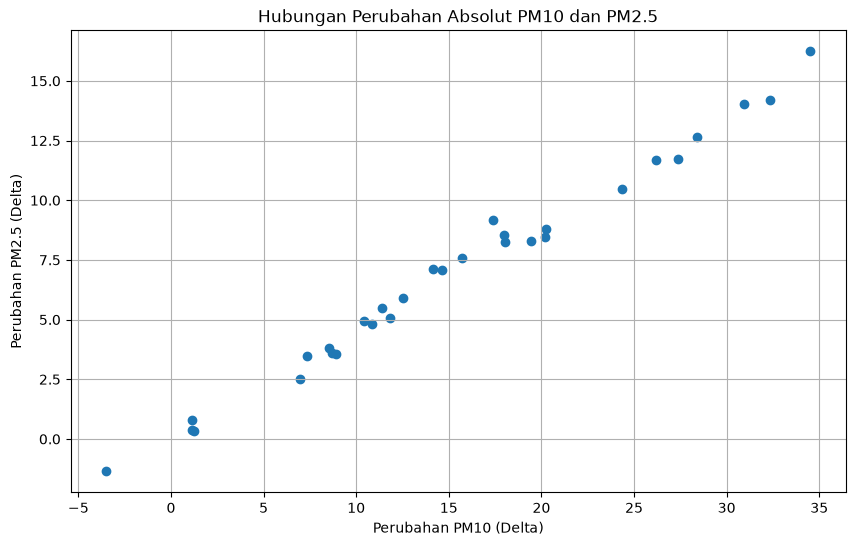

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    sesi_utama_delta["pm10_delta"],
    sesi_utama_delta["pm25_delta"]
)

plt.xlabel("Perubahan PM10 (Delta)")
plt.ylabel("Perubahan PM2.5 (Delta)")
plt.title("Hubungan Perubahan Absolut PM10 dan PM2.5")

plt.grid(True)
plt.show()

In [23]:
korelasi_raw = df[
    ["pm10", "pm25"]
].corr(method="pearson")

display(korelasi_raw.round(4))

,pm10,pm25
pm10,1.000,0.989
pm25,0.989,1.000


In [24]:
korelasi_suhu = df[
    ["suhu", "kelembaban"]
].corr(method="pearson")

display(korelasi_suhu.round(4))

,suhu,kelembaban
suhu,1.0000,-0.8467
kelembaban,-0.8467,1.0000


In [25]:
kolom_sensor = [
    "suhu",
    "kelembaban",
    "pm10",
    "pm25",
    "barometer",
    "tvoc"
]

matriks_korelasi = df[kolom_sensor].corr(
    method="pearson"
)

display(matriks_korelasi.round(3))

,suhu,kelembaban,pm10,pm25,barometer,tvoc
suhu,1.000,-0.847,-0.310,-0.307,0.353,-0.354
kelembaban,-0.847,1.000,0.345,0.338,-0.015,0.016
pm10,-0.310,0.345,1.000,0.989,-0.030,0.026
pm25,-0.307,0.338,0.989,1.000,-0.036,0.032
barometer,0.353,-0.015,-0.030,-0.036,1.000,-1.000
tvoc,-0.354,0.016,0.026,0.032,-1.000,1.000


In [26]:
print("Jumlah nilai unik:")
print(df[["barometer", "tvoc"]].nunique())

print("\nKorelasi Barometer dan TVOC:")
print(df[["barometer", "tvoc"]].corr().round(6))

print("\nContoh data:")
display(df[["barometer", "tvoc"]].head(10))


Jumlah nilai unik:
barometer    2473
tvoc           40
dtype: int64

Korelasi Barometer dan TVOC:
           barometer      tvoc
barometer   1.000000 -0.999678
tvoc       -0.999678  1.000000

Contoh data:


,barometer,tvoc
0,701.29,740.63
1,701.27,740.63
2,701.26,740.63
3,701.26,740.63
4,701.27,740.63
5,701.26,740.63
6,701.26,740.63
7,701.25,740.63
8,701.26,740.63
9,701.26,740.63


In [27]:
# Menghitung frekuensi setiap nilai TVOC
frekuensi_tvoc = (
    df["tvoc"]
    .value_counts()
    .reset_index()
)

frekuensi_tvoc.columns = [
    "nilai_tvoc",
    "jumlah_kemunculan"
]

display(frekuensi_tvoc.head(15))

,nilai_tvoc,jumlah_kemunculan
0,731.70,5131
1,722.78,4510
2,713.87,3573
3,740.63,3531
4,749.56,3034
5,704.97,2361
6,758.50,2104
7,767.45,1787
8,696.08,1385
9,776.40,1162


In [28]:
print("Persentase perubahan nilai TVOC:")

jumlah_perubahan = (
    df["tvoc"].diff().ne(0).sum()
)

persentase = jumlah_perubahan / len(df) * 100

print(round(persentase, 2), "%")

Persentase perubahan nilai TVOC:
2.85 %


In [30]:
# Membuat kelompok ketika nilai TVOC berubah
grup_tvoc = df["tvoc"].ne(df["tvoc"].shift()).cumsum()

# Menghitung durasi setiap kelompok nilai TVOC
durasi_tvoc = df.groupby(grup_tvoc).agg(
    nilai_tvoc=("tvoc", "first"),
    jumlah_data=("tvoc", "size"),
    waktu_mulai=("waktu_tercatat", "min"),
    waktu_selesai=("waktu_tercatat", "max")
).reset_index(drop=True)

# Menghitung durasi dalam menit
durasi_tvoc["durasi_menit"] = (
    durasi_tvoc["waktu_selesai"] -
    durasi_tvoc["waktu_mulai"]
).dt.total_seconds() / 60

display(
    durasi_tvoc.sort_values(
        "durasi_menit",
        ascending=False
    ).head(15).round(2)
)

C:\Users\user\AppData\Local\Temp\ipykernel_12840\2817345910.py:22: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).head(15).round(2)


,nilai_tvoc,jumlah_data,waktu_mulai,waktu_selesai,durasi_menit
758,678.31,160,2026-09-02 07:12:54,2026-09-07 09:25:48,7332.90
710,722.78,49,2026-07-30 10:54:12,2026-08-03 12:07:49,5833.62
298,722.78,135,2026-05-06 08:00:38,2026-05-07 11:48:46,1668.13
694,696.08,122,2026-07-22 08:37:39,2026-07-23 09:56:50,1519.18
932,731.70,399,2026-11-02 18:06:52,2026-11-03 01:16:37,429.75
546,848.34,327,2026-06-08 23:31:25,2026-06-09 05:42:45,371.33
682,1347.66,310,2026-06-27 00:28:21,2026-06-27 06:11:34,343.22
626,722.78,303,2026-06-19 00:14:54,2026-06-19 05:57:58,343.07
901,713.87,294,2026-10-29 00:37:37,2026-10-29 05:45:51,308.23
283,713.87,253,2026-05-05 19:45:20,2026-05-06 00:50:57,305.62


In [31]:
grup_tvoc = (
    df["session_id"].ne(df["session_id"].shift()) |
    df["tvoc"].ne(df["tvoc"].shift())
).cumsum()

durasi_tvoc_sesi = df.groupby(grup_tvoc).agg(
    session_id=("session_id", "first"),
    nilai_tvoc=("tvoc", "first"),
    jumlah_data=("tvoc", "size"),
    waktu_mulai=("waktu_tercatat", "min"),
    waktu_selesai=("waktu_tercatat", "max")
).reset_index(drop=True)

durasi_tvoc_sesi["durasi_menit"] = (
    durasi_tvoc_sesi["waktu_selesai"] -
    durasi_tvoc_sesi["waktu_mulai"]
).dt.total_seconds() / 60

display(
    durasi_tvoc_sesi.sort_values(
        "durasi_menit",
        ascending=False
    ).head(15).round(2)
)

C:\Users\user\AppData\Local\Temp\ipykernel_12840\1492168178.py:23: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).head(15).round(2)


,session_id,nilai_tvoc,jumlah_data,waktu_mulai,waktu_selesai,durasi_menit
936,47,731.70,399,2026-11-02 18:06:52,2026-11-03 01:16:37,429.75
547,19,848.34,327,2026-06-08 23:31:25,2026-06-09 05:42:45,371.33
683,27,1347.66,310,2026-06-27 00:28:21,2026-06-27 06:11:34,343.22
627,25,722.78,303,2026-06-19 00:14:54,2026-06-19 05:57:58,343.07
905,46,713.87,294,2026-10-29 00:37:37,2026-10-29 05:45:51,308.23
283,10,713.87,253,2026-05-05 19:45:20,2026-05-06 00:50:57,305.62
322,11,731.70,247,2026-05-08 01:24:58,2026-05-08 06:25:10,300.20
904,46,704.97,280,2026-10-28 19:41:26,2026-10-29 00:36:34,295.13
402,15,159.13,237,2026-05-19 01:10:35,2026-05-19 06:04:01,293.43
369,14,749.56,230,2026-05-14 00:59:37,2026-05-14 05:50:04,290.45


In [32]:
kolom_sensor = [
    "barometer",
    "tvoc",
    "pm10",
    "pm25"
]

hasil_durasi = []

for sensor in kolom_sensor:

    perubahan = (
        df["session_id"].ne(df["session_id"].shift()) |
        df[sensor].ne(df[sensor].shift())
    )

    grup = perubahan.cumsum()

    ringkasan = df.groupby(grup).agg(
        session_id=("session_id", "first"),
        jumlah_data=(sensor, "size"),
        waktu_mulai=("waktu_tercatat", "min"),
        waktu_selesai=("waktu_tercatat", "max")
    )

    ringkasan["sensor"] = sensor

    ringkasan["durasi_menit"] = (
        ringkasan["waktu_selesai"] -
        ringkasan["waktu_mulai"]
    ).dt.total_seconds() / 60

    hasil_durasi.append(ringkasan)

hasil_durasi = pd.concat(hasil_durasi)

ringkasan_durasi = hasil_durasi.groupby("sensor").agg(
    jumlah_periode=("jumlah_data", "count"),
    rata_rata_data=("jumlah_data", "mean"),
    rata_rata_durasi_menit=("durasi_menit", "mean"),
    durasi_maksimum_menit=("durasi_menit", "max")
).reset_index()

display(ringkasan_durasi.round(2))

,sensor,jumlah_periode,rata_rata_data,rata_rata_durasi_menit,durasi_maksimum_menit
0,barometer,31676,1.22,0.25,7.87
1,pm10,32619,1.18,0.21,30.67
2,pm25,25311,1.52,0.61,32.23
3,tvoc,1101,35.00,40.03,429.75


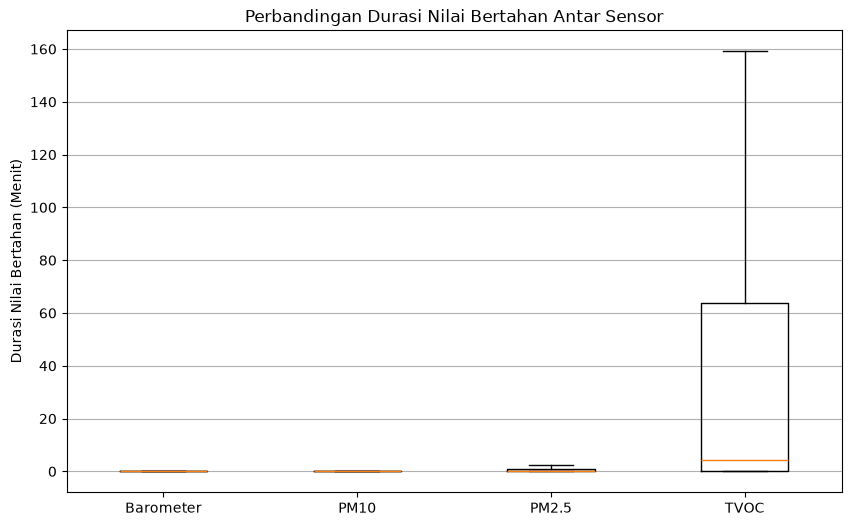

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

data_plot = [
    hasil_durasi[hasil_durasi["sensor"] == sensor]["durasi_menit"]
    for sensor in ["barometer", "pm10", "pm25", "tvoc"]
]

plt.boxplot(
    data_plot,
    tick_labels=["Barometer", "PM10", "PM2.5", "TVOC"],
    showfliers=False
)

plt.ylabel("Durasi Nilai Bertahan (Menit)")
plt.title("Perbandingan Durasi Nilai Bertahan Antar Sensor")
plt.grid(axis="y")
plt.show()

In [34]:
# Pastikan data sudah berurutan berdasarkan waktu
df = df.sort_values("waktu_tercatat").reset_index(drop=True)

# Menandai perubahan nilai TVOC atau pergantian sesi
perubahan_tvoc = (
    df["session_id"].ne(df["session_id"].shift()) |
    df["tvoc"].ne(df["tvoc"].shift())
)

# Membuat kelompok nilai TVOC yang berurutan
grup_tvoc = perubahan_tvoc.cumsum()

# Menghitung waktu pertama setiap kelompok
waktu_awal_tvoc = (
    df.groupby(grup_tvoc)["waktu_tercatat"]
    .transform("first")
)

# Menghitung durasi nilai TVOC bertahan
df["tvoc_duration"] = (
    df["waktu_tercatat"] - waktu_awal_tvoc
).dt.total_seconds() / 60

# Menandai perubahan nilai TVOC
df["tvoc_change_flag"] = (
    perubahan_tvoc.astype(int)
)

# Menghitung perubahan nilai TVOC
df["tvoc_delta"] = (
    df.groupby("session_id")["tvoc"].diff()
)

# Melihat hasil
display(
    df[[
        "session_id",
        "waktu_tercatat",
        "tvoc",
        "tvoc_duration",
        "tvoc_change_flag",
        "tvoc_delta"
    ]].head(20)
)

,session_id,waktu_tercatat,tvoc,tvoc_duration,tvoc_change_flag,tvoc_delta
0,1,2026-01-19 11:40:18,740.63,0.000000,1,NaN
1,1,2026-01-19 11:41:22,740.63,1.066667,0,0.0
2,1,2026-01-19 11:42:27,740.63,2.150000,0,0.0
3,1,2026-01-19 11:43:31,740.63,3.216667,0,0.0
4,1,2026-01-19 11:44:36,740.63,4.300000,0,0.0
5,1,2026-01-19 11:45:41,740.63,5.383333,0,0.0
6,1,2026-01-19 11:46:45,740.63,6.450000,0,0.0
7,1,2026-01-19 11:47:51,740.63,7.550000,0,0.0
8,1,2026-01-19 11:48:58,740.63,8.666667,0,0.0
9,1,2026-01-19 11:50:02,740.63,9.733333,0,0.0


In [35]:
# Mengambil durasi terakhir dari setiap periode TVOC
ringkasan_tvoc = df.groupby(
    [
        "session_id",
        (df["session_id"].ne(df["session_id"].shift()) |
         df["tvoc"].ne(df["tvoc"].shift())).cumsum()
    ]
).agg(
    nilai_tvoc=("tvoc", "first"),
    durasi_maksimum=("tvoc_duration", "max"),
    jumlah_data=("tvoc", "size")
).reset_index()

# Mengurutkan berdasarkan durasi terpanjang
display(
    ringkasan_tvoc.sort_values(
        "durasi_maksimum",
        ascending=False
    ).head(10).round(2)
)

,session_id,level_1,nilai_tvoc,durasi_maksimum,jumlah_data
936,47,937,731.70,429.75,399
547,19,548,848.34,371.33,327
683,27,684,1347.66,343.22,310
627,25,628,722.78,343.07,303
905,46,906,713.87,308.23,294
283,10,284,713.87,305.62,253
322,11,323,731.70,300.20,247
904,46,905,704.97,295.13,280
402,15,403,159.13,293.43,237
369,14,370,749.56,290.45,230


In [36]:
kolom_sensor = [
    "barometer",
    "pm10",
    "pm25",
    "tvoc"
]

for sensor in kolom_sensor:

    perubahan = (
        df["session_id"].ne(df["session_id"].shift()) |
        df[sensor].ne(df[sensor].shift())
    )

    grup = perubahan.cumsum()

    waktu_awal = (
        df.groupby(grup)["waktu_tercatat"]
        .transform("first")
    )

    # Durasi nilai bertahan
    df[f"{sensor}_duration"] = (
        df["waktu_tercatat"] - waktu_awal
    ).dt.total_seconds() / 60

    # Penanda perubahan nilai
    df[f"{sensor}_change_flag"] = perubahan.astype(int)

    # Besar perubahan nilai
    df[f"{sensor}_delta"] = (
        df.groupby("session_id")[sensor].diff()
    )

print("Fitur temporal berhasil dibuat!")

display(df.head(10))

Fitur temporal berhasil dibuat!


,id_monitoring_udara,suhu,kelembaban,pm10,pm25,barometer,tvoc,waktu_tercatat,gap_sec,session_id,...,tvoc_delta,barometer_duration,barometer_change_flag,barometer_delta,pm10_duration,pm10_change_flag,pm10_delta,pm25_duration,pm25_change_flag,pm25_delta
0,164460,29.39,46,8.0,3.0,701.29,740.63,2026-01-19 11:40:18,NaN,1,...,NaN,0.000000,1,NaN,0.0,1,NaN,0.0,1,NaN
1,164461,29.29,46,5.0,2.0,701.27,740.63,2026-01-19 11:41:22,64.0,1,...,0.0,0.000000,1,-0.02,0.0,1,-3.0,0.0,1,-1.0
2,164462,29.39,45,1.0,0.0,701.26,740.63,2026-01-19 11:42:27,65.0,1,...,0.0,0.000000,1,-0.01,0.0,1,-4.0,0.0,1,-2.0
3,164463,29.39,45,4.0,1.0,701.26,740.63,2026-01-19 11:43:31,64.0,1,...,0.0,1.066667,0,0.00,0.0,1,3.0,0.0,1,1.0
4,164464,29.29,44,0.0,0.0,701.27,740.63,2026-01-19 11:44:36,65.0,1,...,0.0,0.000000,1,0.01,0.0,1,-4.0,0.0,1,-1.0
5,164465,29.29,45,8.0,4.0,701.26,740.63,2026-01-19 11:45:41,65.0,1,...,0.0,0.000000,1,-0.01,0.0,1,8.0,0.0,1,4.0
6,164466,29.29,45,2.0,1.0,701.26,740.63,2026-01-19 11:46:45,64.0,1,...,0.0,1.066667,0,0.00,0.0,1,-6.0,0.0,1,-3.0
7,164467,29.29,46,10.0,5.0,701.25,740.63,2026-01-19 11:47:51,66.0,1,...,0.0,0.000000,1,-0.01,0.0,1,8.0,0.0,1,4.0
8,164468,29.29,46,7.0,3.0,701.26,740.63,2026-01-19 11:48:58,67.0,1,...,0.0,0.000000,1,0.01,0.0,1,-3.0,0.0,1,-2.0
9,164469,29.29,45,1.0,0.0,701.26,740.63,2026-01-19 11:50:02,64.0,1,...,0.0,1.066667,0,0.00,0.0,1,-6.0,0.0,1,-3.0


In [37]:
# Periksa jeda pencatatan terbesar dalam setiap sesi
cek_gap = df.groupby("session_id")["gap_sec"].max()

print("Jeda pencatatan terbesar:")
display(cek_gap.sort_values(ascending=False).head(10))

# Periksa jumlah jeda lebih dari 5 menit
print(
    "Jumlah jeda lebih dari 5 menit:",
    (df["gap_sec"] > 300).sum()
)

Jeda pencatatan terbesar:


session_id
44    3716448.0
5     3543396.0
40    2152128.0
28    1735898.0
6     1474388.0
3     1384347.0
17    1038795.0
7      605362.0
10     603360.0
2      521773.0
Name: gap_sec, dtype: float64

Jumlah jeda lebih dari 5 menit: 100


In [38]:
kolom_cek = [
    "session_id",
    "waktu_tercatat",
    "gap_sec",
    "tvoc",
    "barometer",
    "pm10",
    "pm25"
]

display(
    df.sort_values(
        "gap_sec",
        ascending=False
    )[kolom_cek].head(10)
)

,session_id,waktu_tercatat,gap_sec,tvoc,barometer,pm10,pm25
29480,44,2026-10-22 10:20:29,3716448.0,767.45,699.19,5.0,2.0
3453,5,2026-03-26 09:46:52,3543396.0,731.70,702.09,4.0,2.0
25055,40,2026-08-28 09:56:37,2152128.0,687.19,705.42,24.0,12.0
24588,28,2026-07-17 11:30:46,1735898.0,704.97,703.97,36.0,17.0
4664,6,2026-04-13 10:53:24,1474388.0,776.40,698.32,18.0,11.0
2425,3,2026-02-12 10:36:31,1384347.0,758.50,699.88,27.0,14.0
15761,17,2026-06-02 10:03:17,1038795.0,722.78,702.65,10.0,4.0
5855,7,2026-04-21 10:11:05,605362.0,722.78,702.29,16.0,6.0
9109,10,2026-05-05 09:24:27,603360.0,713.87,703.42,49.0,23.0
1136,2,2026-01-26 09:56:12,521773.0,704.97,704.04,16.0,8.0


In [39]:
# Mencari jeda lebih dari 5 menit
# tetapi masih dalam session_id yang sama

mask_gap = (
    (df["gap_sec"] > 300) &
    (df["session_id"] == df["session_id"].shift())
)

kolom_cek = [
    "session_id",
    "waktu_tercatat",
    "gap_sec",
    "tvoc",
    "barometer",
    "pm10",
    "pm25"
]

data_gap_internal = df.loc[mask_gap, kolom_cek]

print("Jumlah jeda lebih dari 5 menit di dalam sesi:",
      len(data_gap_internal))

display(data_gap_internal.head(15))

Jumlah jeda lebih dari 5 menit di dalam sesi: 49


,session_id,waktu_tercatat,gap_sec,tvoc,barometer,pm10,pm25
51,1,2026-01-19 13:30:22,3369.0,758.50,699.99,19.0,10.0
2435,3,2026-02-12 10:54:51,526.0,758.50,699.70,16.0,9.0
2562,3,2026-02-12 13:33:06,405.0,776.40,698.08,0.0,0.0
2611,3,2026-02-12 14:33:27,306.0,776.40,697.82,0.0,0.0
2699,3,2026-02-12 16:24:52,380.0,776.40,697.83,0.0,0.0
2727,4,2026-02-12 18:54:50,305.0,758.50,699.46,21.0,11.0
4344,5,2026-03-27 02:59:27,373.0,740.63,701.33,32.0,15.0
6858,7,2026-04-22 08:41:12,372.0,722.78,702.68,40.0,18.0
7330,8,2026-04-23 19:38:22,373.0,740.63,700.92,47.0,22.0
7379,8,2026-04-23 20:54:27,450.0,731.70,701.57,55.0,25.0


In [40]:
kolom_sensor = [
    "barometer",
    "pm10",
    "pm25",
    "tvoc"
]

for sensor in kolom_sensor:

    # Perubahan nilai sensor
    perubahan_nilai = df[sensor].ne(df[sensor].shift())

    # Pergantian sesi
    pergantian_sesi = df["session_id"].ne(
        df["session_id"].shift()
    )

    # Jeda pencatatan lebih dari 5 menit
    jeda_panjang = df["gap_sec"] > 300

    # Awal periode baru
    periode_baru = (
        perubahan_nilai |
        pergantian_sesi |
        jeda_panjang
    )

    grup = periode_baru.cumsum()

    # Waktu awal periode
    waktu_awal = (
        df.groupby(grup)["waktu_tercatat"]
        .transform("first")
    )

    # Hitung ulang durasi
    df[f"{sensor}_duration"] = (
        df["waktu_tercatat"] - waktu_awal
    ).dt.total_seconds() / 60

print("Perhitungan durasi berhasil diperbarui!")

Perhitungan durasi berhasil diperbarui!


In [41]:
display(
    df.loc[45:55, [
        "session_id",
        "waktu_tercatat",
        "gap_sec",
        "tvoc",
        "tvoc_duration",
        "barometer_duration",
        "pm10_duration",
        "pm25_duration"
    ]].round(2)
)

C:\Users\user\AppData\Local\Temp\ipykernel_12840\352238088.py:11: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ]].round(2)


,session_id,waktu_tercatat,gap_sec,tvoc,tvoc_duration,barometer_duration,pm10_duration,pm25_duration
45,1,2026-01-19 12:28:49,65.0,749.56,1.08,0.00,0.00,2.15
46,1,2026-01-19 12:29:54,65.0,749.56,2.17,1.08,0.00,3.23
47,1,2026-01-19 12:30:58,64.0,749.56,3.23,0.00,0.00,0.00
48,1,2026-01-19 12:32:03,65.0,749.56,4.32,0.00,0.00,0.00
49,1,2026-01-19 12:33:08,65.0,749.56,5.40,0.00,0.00,0.00
50,1,2026-01-19 12:34:13,65.0,749.56,6.48,0.00,0.00,0.00
51,1,2026-01-19 13:30:22,3369.0,758.50,0.00,0.00,0.00,0.00
52,1,2026-01-19 13:31:26,64.0,758.50,1.07,0.00,1.07,0.00
53,1,2026-01-19 13:32:31,65.0,758.50,2.15,0.00,0.00,0.00
54,1,2026-01-19 13:33:36,65.0,758.50,3.23,0.00,0.00,0.00


In [42]:
mask_internal = (
    (df["session_id"] == df["session_id"].shift()) &
    df["gap_sec"].notna()
)

display(
    df.loc[mask_internal, "gap_sec"]
    .describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99])
)

count    38479.000000
mean        71.123340
std         44.646424
min         13.000000
50%         63.000000
75%         65.000000
90%         68.000000
95%        141.000000
99%        217.000000
max       3369.000000
Name: gap_sec, dtype: float64

In [43]:
jeda_panjang_internal = df.loc[
    mask_internal & (df["gap_sec"] > 300),
    ["session_id", "waktu_tercatat", "gap_sec"]
]

print("Jumlah jeda lebih dari 300 detik:",
      len(jeda_panjang_internal))

display(jeda_panjang_internal.describe())

Jumlah jeda lebih dari 300 detik: 49


,session_id,waktu_tercatat,gap_sec
count,49.000000,49,49.000000
mean,20.244898,2026-06-06 03:07:50.020408,732.102041
min,1.000000,2026-01-19 13:30:22,301.000000
25%,9.000000,2026-04-27 14:26:26,311.000000
50%,15.000000,2026-05-19 00:43:12,380.000000
75%,34.000000,2026-07-27 13:45:17,484.000000
max,50.000000,2026-11-12 21:48:57,3369.000000
std,14.926948,NaN,819.537655


In [44]:
# Menandai jeda pencatatan lebih dari 5 menit
df["gap_panjang_flag"] = (
    df["gap_sec"] > 300
).astype(int)

print("Jumlah jeda panjang:",
      df["gap_panjang_flag"].sum())

print("Persentase jeda panjang:",
      round(df["gap_panjang_flag"].mean() * 100, 3), "%")

display(
    df.loc[df["gap_panjang_flag"] == 1, [
        "session_id",
        "waktu_tercatat",
        "gap_sec",
        "gap_panjang_flag"
    ]].head(10)
)

Jumlah jeda panjang: 100
Persentase jeda panjang: 0.26 %


,session_id,waktu_tercatat,gap_sec,gap_panjang_flag
51,1,2026-01-19 13:30:22,3369.0,1
1136,2,2026-01-26 09:56:12,521773.0,1
2425,3,2026-02-12 10:36:31,1384347.0,1
2435,3,2026-02-12 10:54:51,526.0,1
2562,3,2026-02-12 13:33:06,405.0,1
2611,3,2026-02-12 14:33:27,306.0,1
2699,3,2026-02-12 16:24:52,380.0,1
2707,4,2026-02-12 18:25:52,6729.0,1
2727,4,2026-02-12 18:54:50,305.0,1
3453,5,2026-03-26 09:46:52,3543396.0,1


In [45]:
# Memastikan baris masih berada dalam sesi yang sama
masih_dalam_sesi = (
    df["session_id"] == df["session_id"].shift()
)

# Menandai jeda lebih dari 5 menit di dalam sesi
df["gap_panjang_flag"] = (
    masih_dalam_sesi & (df["gap_sec"] > 300)
).astype(int)

print(
    "Jumlah jeda panjang dalam sesi:",
    df["gap_panjang_flag"].sum()
)

print(
    "Persentase:",
    round(df["gap_panjang_flag"].mean() * 100, 3),
    "%"
)

display(
    df.loc[df["gap_panjang_flag"] == 1, [
        "session_id",
        "waktu_tercatat",
        "gap_sec",
        "gap_panjang_flag"
    ]].head(10)
)

Jumlah jeda panjang dalam sesi: 49
Persentase: 0.127 %


,session_id,waktu_tercatat,gap_sec,gap_panjang_flag
51,1,2026-01-19 13:30:22,3369.0,1
2435,3,2026-02-12 10:54:51,526.0,1
2562,3,2026-02-12 13:33:06,405.0,1
2611,3,2026-02-12 14:33:27,306.0,1
2699,3,2026-02-12 16:24:52,380.0,1
2727,4,2026-02-12 18:54:50,305.0,1
4344,5,2026-03-27 02:59:27,373.0,1
6858,7,2026-04-22 08:41:12,372.0,1
7330,8,2026-04-23 19:38:22,373.0,1
7379,8,2026-04-23 20:54:27,450.0,1


In [46]:
kolom_fitur = [
    "barometer_duration",
    "pm10_duration",
    "pm25_duration",
    "tvoc_duration",
    "barometer_change_flag",
    "pm10_change_flag",
    "pm25_change_flag",
    "tvoc_change_flag",
    "barometer_delta",
    "pm10_delta",
    "pm25_delta",
    "tvoc_delta",
    "gap_panjang_flag"
]

print("Jumlah fitur:", len(kolom_fitur))

display(df[kolom_fitur].describe().round(2))

print("\nJumlah nilai kosong:")
display(df[kolom_fitur].isnull().sum())

Jumlah fitur: 13


,barometer_duration,pm10_duration,pm25_duration,tvoc_duration,barometer_change_flag,pm10_change_flag,pm25_change_flag,tvoc_change_flag,barometer_delta,pm10_delta,pm25_delta,tvoc_delta,gap_panjang_flag
count,38531.00,38531.00,38531.00,38531.00,38531.00,38531.00,38531.00,38531.00,38479.00,38479.0,38479.00,38479.00,38531.00
mean,0.25,0.24,0.75,66.22,0.82,0.85,0.66,0.03,-0.00,0.0,0.00,0.00,0.00
std,0.62,0.86,1.58,64.06,0.38,0.36,0.47,0.17,0.03,6.5,3.11,1.47,0.04
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,-0.61,-454.0,-204.00,-9.49,0.00
25%,0.00,0.00,0.00,19.18,1.00,1.00,0.00,0.00,-0.02,-2.0,-1.00,0.00,0.00
50%,0.00,0.00,0.00,47.28,1.00,1.00,1.00,0.00,0.00,0.0,0.00,0.00,0.00
75%,0.00,0.00,1.05,93.02,1.00,1.00,1.00,0.00,0.02,2.0,1.00,0.00,0.00
max,7.87,30.67,32.23,429.75,1.00,1.00,1.00,1.00,0.56,470.0,211.00,9.49,1.00



Jumlah nilai kosong:


barometer_duration        0
pm10_duration             0
pm25_duration             0
tvoc_duration             0
barometer_change_flag     0
pm10_change_flag          0
pm25_change_flag          0
tvoc_change_flag          0
barometer_delta          52
pm10_delta               52
pm25_delta               52
tvoc_delta               52
gap_panjang_flag          0
dtype: int64

In [47]:
kolom_delta = [
    "barometer_delta",
    "pm10_delta",
    "pm25_delta",
    "tvoc_delta"
]

for kolom in kolom_delta:
    print(
        kolom,
        "Jumlah NaN:", df[kolom].isna().sum()
    )

display(
    df.loc[
        df[kolom_delta].isna().any(axis=1),
        ["session_id", "waktu_tercatat"] + kolom_delta
    ].head(15)
)

barometer_delta Jumlah NaN: 52
pm10_delta Jumlah NaN: 52
pm25_delta Jumlah NaN: 52
tvoc_delta Jumlah NaN: 52


,session_id,waktu_tercatat,barometer_delta,pm10_delta,pm25_delta,tvoc_delta
0,1,2026-01-19 11:40:18,NaN,NaN,NaN,NaN
1136,2,2026-01-26 09:56:12,NaN,NaN,NaN,NaN
2425,3,2026-02-12 10:36:31,NaN,NaN,NaN,NaN
2707,4,2026-02-12 18:25:52,NaN,NaN,NaN,NaN
3453,5,2026-03-26 09:46:52,NaN,NaN,NaN,NaN
4664,6,2026-04-13 10:53:24,NaN,NaN,NaN,NaN
5855,7,2026-04-21 10:11:05,NaN,NaN,NaN,NaN
6920,8,2026-04-23 10:04:03,NaN,NaN,NaN,NaN
7966,9,2026-04-27 10:08:28,NaN,NaN,NaN,NaN
9109,10,2026-05-05 09:24:27,NaN,NaN,NaN,NaN


In [48]:
kolom_delta = [
    "barometer_delta",
    "pm10_delta",
    "pm25_delta",
    "tvoc_delta"
]

# Tandai baris awal sesi
df["awal_sesi_flag"] = (
    df["session_id"] != df["session_id"].shift()
).astype(int)

# Isi NaN pada delta dengan 0
df[kolom_delta] = df[kolom_delta].fillna(0)

print("Jumlah nilai kosong setelah diperbaiki:")
display(df[kolom_delta].isna().sum())

print("\nJumlah awal sesi:",
      df["awal_sesi_flag"].sum())

Jumlah nilai kosong setelah diperbaiki:


barometer_delta    0
pm10_delta         0
pm25_delta         0
tvoc_delta         0
dtype: int64


Jumlah awal sesi: 52


In [49]:
import numpy as np

kolom_fitur = [
    "barometer_duration",
    "pm10_duration",
    "pm25_duration",
    "tvoc_duration",
    "barometer_change_flag",
    "pm10_change_flag",
    "pm25_change_flag",
    "tvoc_change_flag",
    "barometer_delta",
    "pm10_delta",
    "pm25_delta",
    "tvoc_delta",
    "gap_panjang_flag",
    "awal_sesi_flag"
]

print("Jumlah nilai kosong:")
print(df[kolom_fitur].isna().sum().sum())

print("\nJumlah nilai tak terhingga:")
print(np.isinf(df[kolom_fitur]).sum().sum())

print("\nJumlah fitur:", len(kolom_fitur))
print("Jumlah baris:", len(df))

Jumlah nilai kosong:
0

Jumlah nilai tak terhingga:
0

Jumlah fitur: 14
Jumlah baris: 38531


In [50]:
import os

folder_output = r"C:\AI-Anomaly-Detection\outputs"

os.makedirs(folder_output, exist_ok=True)

file_output = os.path.join(
    folder_output,
    "dataset_feature_engineering.csv"
)

df.to_csv(file_output, index=False)

print("Dataset berhasil disimpan!")
print(file_output)

Dataset berhasil disimpan!
C:\AI-Anomaly-Detection\outputs\dataset_feature_engineering.csv
